# 📊 De la incertidumbre a los datos: probabilidad y estadística con Matplotlib

### SIC — Inteligencia Artificial | Capítulo 4: Probabilidad y Estadística

Este Colab **no es un curso de Matplotlib con probabilidad al final**. Es un recorrido en el que cada herramienta visual aparece porque la necesitamos para responder una pregunta estadística concreta. Matplotlib es el idioma; la probabilidad y la estadística son la conversación.

**El recorrido:**

```
TENEMOS INCERTIDUMBRE
        ↓
LA MODELAMOS CON PROBABILIDAD
        ↓
GENERAMOS / OBSERVAMOS DATOS
        ↓
LOS VISUALIZAMOS
        ↓
IDENTIFICAMOS DISTRIBUCIONES
        ↓
TOMAMOS MUESTRAS
        ↓
CUANTIFICAMOS INCERTIDUMBRE
        ↓
SACAMOS CONCLUSIONES
```

| Parte | Pregunta que responde |
|---|---|
| **0. Matplotlib mínimo** | ¿Cuál es la receta base de cualquier gráfico? |
| **1. Aleatoriedad** | ¿Qué significa que un resultado sea incierto? |
| **2. Una variable** | ¿Cómo se distribuyen los datos que observo? |
| **3. Variable aleatoria** | ¿Cómo convierto un resultado en un número? |
| **4. Distribuciones** | ¿Qué modelo teórico podría generar estos datos? |
| **5 a 7. Varias variables** | ¿Están relacionadas dos (o más) variables? |
| **8. EDA real** | ¿Qué patrones hay en un dataset real? |
| **9. Muestreo y TLC** | ¿Qué pasa si repito el experimento muchas veces? |
| **10-11. Inferencia** | ¿Qué puedo afirmar sobre la población a partir de una muestra? |
| **12. Laboratorio integrador** | ¿Puedo aplicar todo el pipeline a un dataset nuevo? |

El catálogo de estilos de Matplotlib (colores, grillas, marcadores) y el bonus de pronóstico con Prophet quedaron como **Anexos** al final: son útiles, pero no son parte del hilo conceptual de probabilidad y estadística.

---


> 🧭 **Cómo usar este Colab:** cada vez que veas el ícono 🎨 hay una **plantilla editable**:
> una celda de código con un bloque de variables al principio (colores, etiquetas, grillas,
> tamaños...) pensada para que la modifiques y la vuelvas a correr las veces que quieras.
> Cada vez que veas ✏️ hay un **ejercicio propuesto** para practicar con tus propios datos.
> No hace falta hacerlos en orden estricto, pero sí conviene correr las celdas de arriba
> hacia abajo la primera vez (varias reutilizan variables ya definidas).

## 0. Setup

Importamos todo lo que vamos a usar en el Colab. Fijamos una semilla (`rng`) para que los
datos aleatorios sean **reproducibles**: si corren el notebook de nuevo, van a ver los mismos
gráficos.

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn import datasets

# Semilla reproducible: siempre generamos los mismos "datos aleatorios"
rng = np.random.default_rng(42)

print("Setup listo ✅")

Setup listo ✅


In [71]:
type(rng)

numpy.random._generator.Generator

---
# PARTE 0 — Matplotlib mínimo

Antes de hablar de probabilidad necesitamos lo justo y necesario para dibujar algo. **No vamos a ver diez tipos de gráfico de entrada** — solo el template base, que vamos a reutilizar durante todo el Colab cambiando una sola línea (`ax.hist`, `ax.bar`, `ax.scatter`, `ax.boxplot`...). El resto de las opciones de estilo (colores, marcadores, grillas) las vamos a ir necesitando de a poco; el catálogo completo queda en el **Anexo A**, al final, para consultar cuando haga falta.


## Bloque 1 — El template universal

Casi todo gráfico en Matplotlib sigue la misma receta mental:

```
FIGURA → EJES → DATOS → TIPO DE GRÁFICO → ETIQUETAS → INTERPRETACIÓN
```

Este es el **template base de todo el Colab**. Lo vamos a reutilizar una y otra vez, cambiando
solo la línea que dibuja los datos (`ax.plot`, `ax.scatter`, `ax.bar`, `ax.hist`, `ax.boxplot`...).

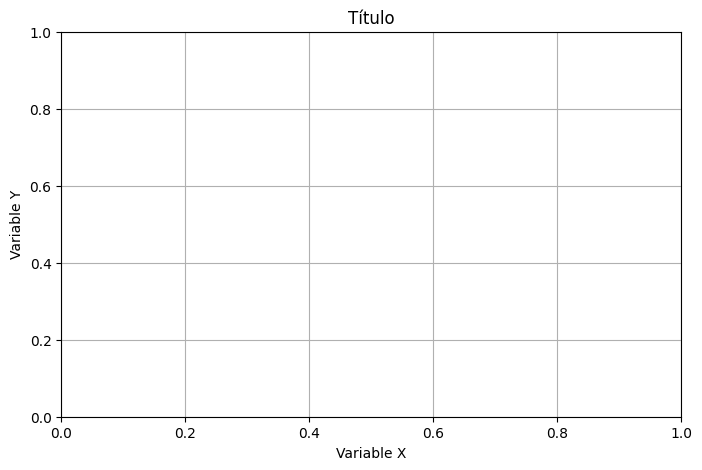

In [72]:
# Template universal (sin datos todavía, solo la estructura)
fig, ax = plt.subplots(figsize=(8, 5))

# <-- acá va el gráfico -->

ax.set_title("Título")
ax.set_xlabel("Variable X")
ax.set_ylabel("Variable Y")
ax.grid()

plt.show()

Ahora completamos el template con datos reales y usamos `ax.plot`:

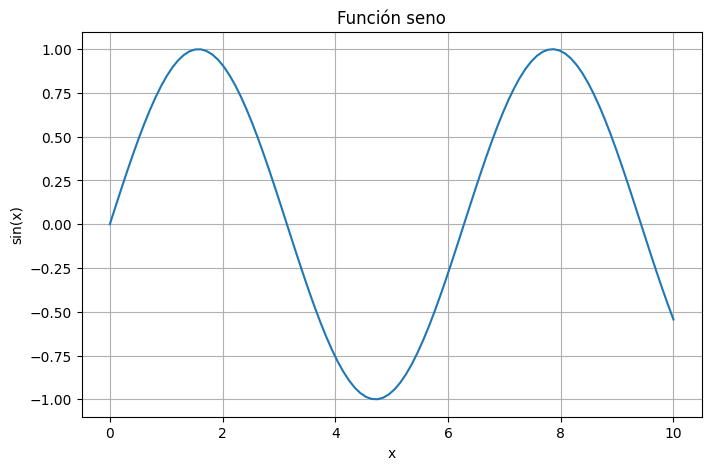

In [73]:
x = np.linspace(0, 10, 100)
y = np.sin(x)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, y)

ax.set_title("Función seno")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
ax.grid()

plt.show()

---
# PARTE 1 — ¿Qué significa que algo sea aleatorio?

Antes de graficar cualquier dato, necesitamos el vocabulario básico de probabilidad. Lo vamos a construir con el ejemplo más simple posible: **tirar una moneda**.

```
EXPERIMENTO ALEATORIO
   Lanzar una moneda
        ↓
ESPACIO MUESTRAL (todos los resultados posibles)
   S = {cara, cruz}
        ↓
EVENTO (un subconjunto de S que nos interesa)
   A = "sale cara"
```

La **probabilidad teórica** de A es `P(A) = 1/2`. Pero, ¿qué pasa si tiramos la moneda muchas veces y contamos?


In [74]:
rng

Generator(PCG64) at 0x7C7B8295C580

In [75]:
# Simulamos 10 tiradas de una moneda
monedas = rng.choice(["Cara", "Cruz"], size=10)
monedas


array(['Cara', 'Cruz', 'Cruz', 'Cara', 'Cara', 'Cruz', 'Cara', 'Cruz',
       'Cara', 'Cara'], dtype='<U4')

Con 10 tiradas es difícil sacar conclusiones. Repitamos el experimento 10.000 veces y miremos la **frecuencia relativa** de cada resultado:


In [76]:
np.unique(monedas, return_counts=True)

(array(['Cara', 'Cruz'], dtype='<U4'), array([6, 4]))

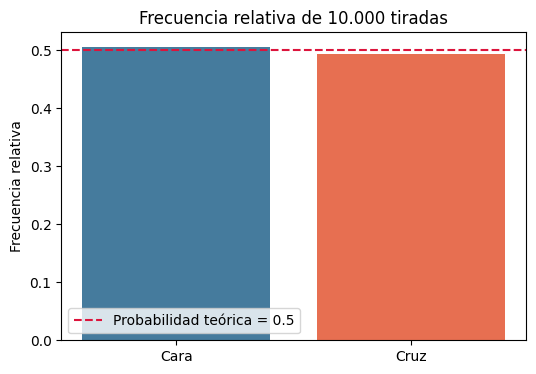

array([0.506, 0.494])

In [77]:
monedas = rng.choice(["Cara", "Cruz"], size=10000)

valores, frecuencias = np.unique(monedas, return_counts=True)
frecuencia_relativa = frecuencias / len(monedas)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(valores, frecuencia_relativa, color=["#457b9d", "#e76f51"])
ax.axhline(0.5, color="crimson", linestyle="--", label="Probabilidad teórica = 0.5")
ax.set_title("Frecuencia relativa de 10.000 tiradas")
ax.set_ylabel("Frecuencia relativa")
ax.legend()
plt.show()

frecuencia_relativa


**Idea clave — probabilidad empírica vs. teórica:**

```
Probabilidad teórica  ≠  siempre exactamente igual a la frecuencia observada

Pero:

más experimentos
        ↓
la frecuencia relativa
        ↓
se estabiliza cerca de la probabilidad teórica
```

Esto es la (informal) **ley de los grandes números**. Vamos a ver el mismo patrón con un experimento que tiene más de dos resultados posibles: **tirar un dado**.


## Bloque 3 — Una variable discreta: barras de frecuencia

Simulamos 1000 tiradas de un dado (valores discretos del 1 al 6).

In [78]:
x.shape

(100,)

In [79]:
valores

array(['Cara', 'Cruz'], dtype='<U4')

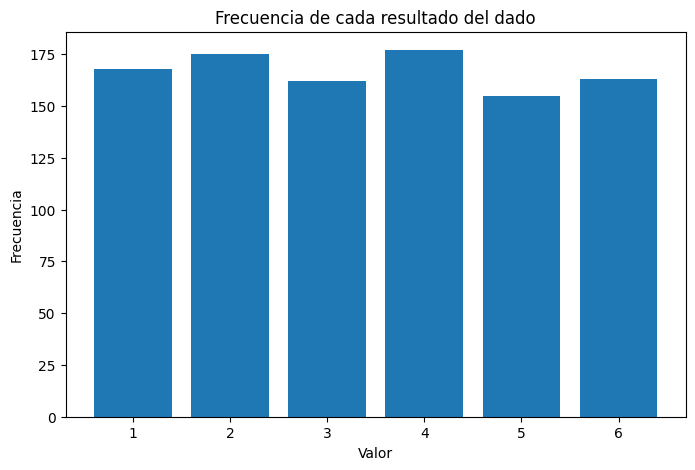

In [80]:
x = rng.integers(
    low=1,
    high=7,   # high es exclusivo -> genera 1..6
    size=1000
)

valores, frecuencias = np.unique(x, return_counts=True)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(valores, frecuencias)

ax.set_title("Frecuencia de cada resultado del dado")
ax.set_xlabel("Valor")
ax.set_ylabel("Frecuencia")

plt.show()

**Reglas básicas de probabilidad**, ilustradas con el dado (S = {1,2,3,4,5,6}):

- **Evento**: A = "sale par" = {2, 4, 6} → `P(A) = 3/6 = 0.5`
- **Complemento**: Aᶜ = "sale impar" → `P(Aᶜ) = 1 - P(A)`
- **Unión**: B = "sale más de 4" = {5, 6} → A ∪ B = "par o más de 4" = {2, 4, 5, 6}
- **Intersección**: A ∩ B = "par y más de 4" = {6}

Comprobemos empíricamente `P(par)` con la misma simulación de 1000 tiradas:


In [81]:
es_par = (x % 2 == 0)

print("P(par) empírica  :", round(es_par.mean(), 3))
print("P(par) teórica   :", round(3/6, 3))


P(par) empírica  : 0.515
P(par) teórica   : 0.5


**Probabilidad condicional y Bayes (adelanto):** más adelante vamos a trabajar con datos que tienen varias variables a la vez (por ejemplo, horas de estudio y si un/a estudiante aprobó o no). Ahí la pregunta natural deja de ser "¿cuál es P(aprobar)?" y pasa a ser:

```
P(aprobar | estudió más de 5 horas)
```

es decir, *P(A dado que ya sabemos que pasó B)*. La fórmula que conecta ambas direcciones (de `P(A|B)` a `P(B|A)`) es el **teorema de Bayes**:

```
P(A|B) = P(B|A) · P(A) / P(B)
```

La vamos a retomar en la Parte 5, cuando tengamos datos reales de dos variables para calcularla.


---
# PARTE 2 — Una variable: ¿cómo se distribuyen los datos?

```
Datos individuales
72, 65, 81, 74, 68, 90, 55, ...
        ↓
¿Podemos entender 200 números mirando la lista?
        ↓
NO
        ↓
Necesitamos agruparlos
        ↓
HISTOGRAMA
        ↓
DISTRIBUCIÓN
```

Empecemos con una variable **continua**: 1000 valores que podrían ser alturas, temperaturas o tiempos de reacción.


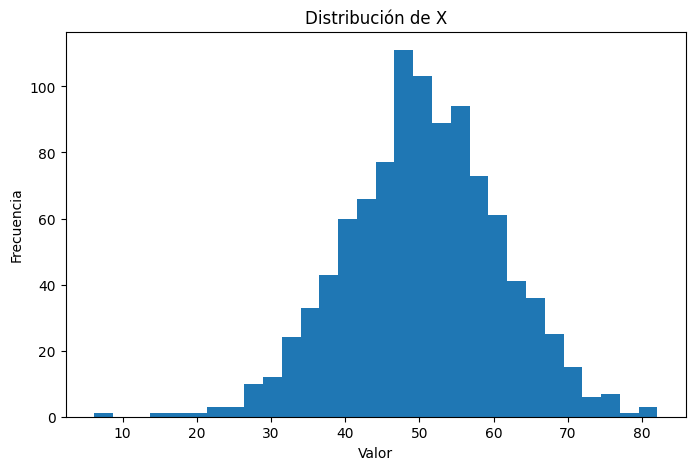

In [82]:
x = rng.normal(
    loc=50,
    scale=10,
    size=1000
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(x, bins=30)

ax.set_title("Distribución de X")
ax.set_xlabel("Valor")
ax.set_ylabel("Frecuencia")

plt.show()

Un histograma hace esto:

```
DATOS INDIVIDUALES → AGRUPACIÓN EN BINS → DISTRIBUCIÓN
```

**Experimento:** cambiemos el número de bins y comparemos.

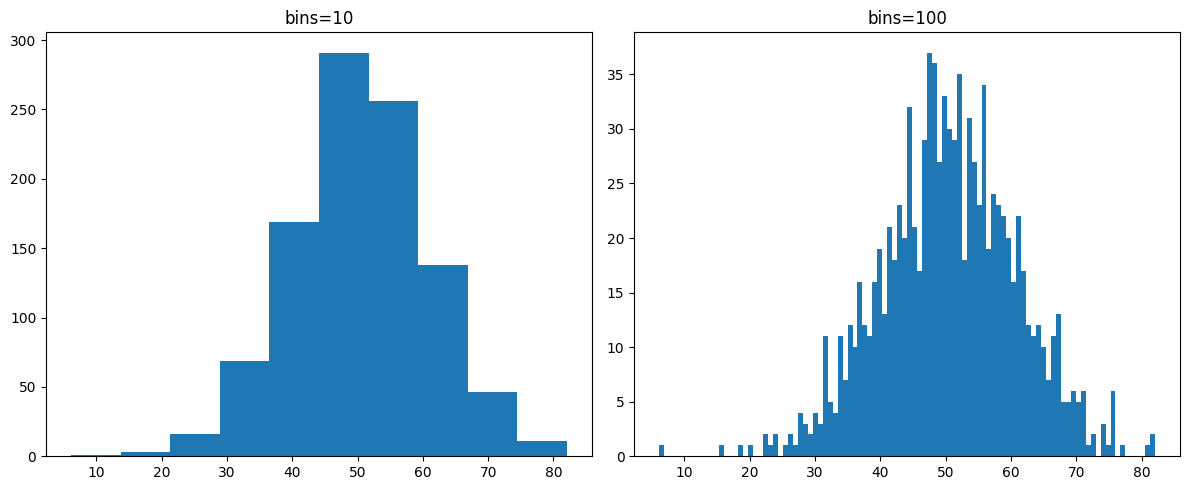

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(x, bins=10)
axes[0].set_title("bins=10")

axes[1].hist(x, bins=100)
axes[1].set_title("bins=100")

plt.tight_layout()
plt.show()

### 🎨 Plantilla editable — Histograma

Ejemplo de la vida real: notas de un examen (0 a 100) de un curso de 200 estudiantes.

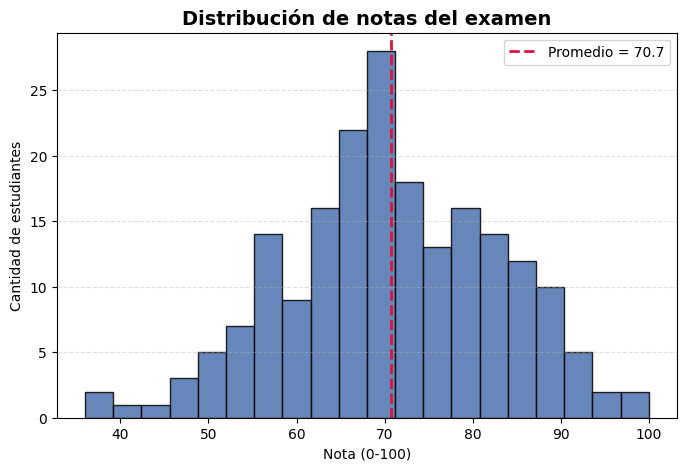

In [84]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
media_notas           = 70
desvio_notas          = 12
cantidad_estudiantes  = 200

color_barras   = "#4C72B0"
color_borde    = "black"
transparencia  = 0.85
cantidad_bins  = 20

titulo     = "Distribución de notas del examen"
etiqueta_x = "Nota (0-100)"
etiqueta_y = "Cantidad de estudiantes"
# ============================================

notas = rng.normal(media_notas, desvio_notas, cantidad_estudiantes)
notas = np.clip(notas, 0, 100)  # una nota no puede ser negativa ni mayor a 100

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    notas,
    bins=cantidad_bins,
    color=color_barras,
    edgecolor=color_borde,
    alpha=transparencia,
)

ax.axvline(
    notas.mean(), color="crimson", linestyle="--", linewidth=2,
    label=f"Promedio = {notas.mean():.1f}",
)

ax.set_title(titulo, fontsize=14, fontweight="bold")
ax.set_xlabel(etiqueta_x)
ax.set_ylabel(etiqueta_y)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.show()

✏️ **Ejercicio:**
1. Simulá un examen más difícil: `media_notas = 55`, `desvio_notas = 18`. ¿Cuántos estudiantes
   quedarían por debajo de 40? (pista: `(notas < 40).sum()`)
2. Agregá una segunda línea vertical con la **mediana** (`np.median(notas)`), en otro color.
3. Probá `cantidad_bins = 5` y `cantidad_bins = 60`. ¿En qué punto el gráfico deja de ser útil?

**Pregunta clave:** ¿cambió la distribución subyacente de los datos, o cambió nuestra
**forma de verla**? (Los datos son los mismos en los dos gráficos — solo cambia cómo los
agrupamos). Esta idea es fundamental antes de entrar formalmente en EDA.

**Continua vs. discreta:**

| Tipo de variable | Gráfico natural |
|---|---|
| Continua | Histograma (`ax.hist`) |
| Discreta | Barras de frecuencia (`ax.bar` sobre valores únicos) |

Técnicamente también podríamos usar `hist` para datos discretos, pero visualmente cambia la
interpretación (bins vs. categorías exactas).

---
# PARTE 3 — De un resultado a un número: la variable aleatoria

Hasta acá trabajamos con resultados ("cara", "cruz", el número del dado). Para poder calcular con `scipy.stats` necesitamos convertir cada resultado en un **número**. Eso es exactamente lo que hace una **variable aleatoria**: una función que asigna un número a cada resultado del experimento.

```
EXPERIMENTO
     │
     ▼
RESULTADOS
Cara / Cruz
     │
     ▼
VARIABLE ALEATORIA X
     │
     ├── Cara → 1
     └── Cruz → 0
     │
     ▼
DISTRIBUCIÓN DE PROBABILIDAD
```

Esta X (1 si sale cara, 0 si sale cruz) es una variable aleatoria **discreta** de tipo **Bernoulli**. Ahora `scipy.stats` deja de ser una caja mágica: `stats.bernoulli.pmf(x, p)` simplemente nos da `P(X = x)`.


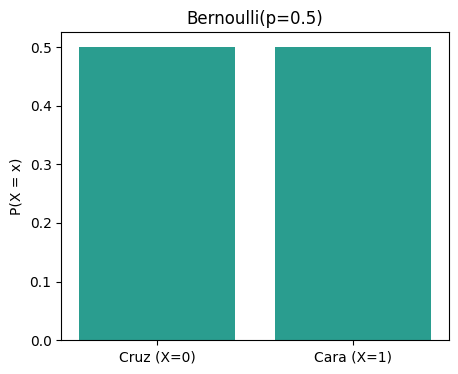

In [85]:
p_cara = 0.5
x_bernoulli = [0, 1]
y_bernoulli = stats.bernoulli.pmf(x_bernoulli, p_cara)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(x_bernoulli, y_bernoulli, tick_label=["Cruz (X=0)", "Cara (X=1)"], color="#2a9d8f")
ax.set_title(f"Bernoulli(p={p_cara})")
ax.set_ylabel("P(X = x)")
plt.show()


Una variable aleatoria puede ser:

- **Discreta**: toma valores puntuales y contables (el resultado de un dado, la cantidad de llamadas en un minuto).
- **Continua**: toma cualquier valor dentro de un rango (una altura, un tiempo, un peso).

En la Parte 4 vamos a ver ambos casos con `scipy.stats`.


---
# PARTE 4 — ¿Qué distribución podría modelar estos datos?

```
DATOS REALES
      │
      ▼
 HISTOGRAMA
      │
      ▼
 ¿QUÉ FORMA TIENE?
      │
      ▼
 ¿Qué distribución teórica podría modelarla?
      │
      ▼
NORMAL / POISSON / BINOMIAL / ...
      │
      ▼
CALCULAMOS PROBABILIDADES
```

`scipy.stats` nos da esas distribuciones teóricas ya armadas. Empecemos por la más usada: la **normal**.


## Bloque 11 — `scipy.stats`: template general de una distribución

El template para dibujar cualquier distribución teórica es siempre el mismo:

```python
x = np.linspace(inicio, fin, 1000)
y = distribucion.pdf(x, parametros)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y)
plt.show()
```

Empecemos con la distribución normal estándar:

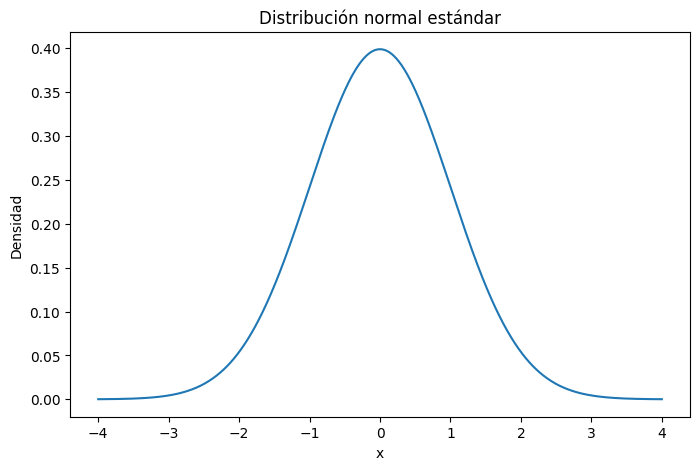

In [86]:
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x, loc=0, scale=1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y)
ax.set_title("Distribución normal estándar")
ax.set_xlabel("x")
ax.set_ylabel("Densidad")
plt.show()

**Experimento 1 — ¿qué mueve `loc`?**

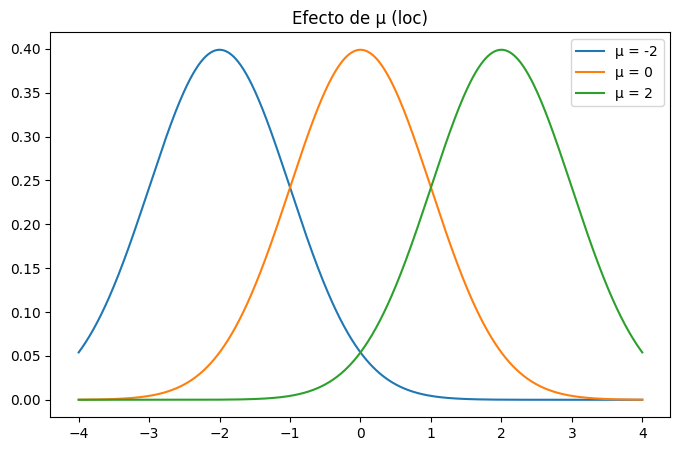

In [87]:
fig, ax = plt.subplots(figsize=(8, 5))

for media in [-2, 0, 2]:
    y = stats.norm.pdf(x, loc=media, scale=1)
    ax.plot(x, y, label=f"μ = {media}")

ax.set_title("Efecto de μ (loc)")
ax.legend()
plt.show()

**Experimento 2 — ¿qué mueve `scale`?**

**Antes de correr el código:** si aumentamos `sigma`, ¿qué va a pasar con la curva?

```
A) Se mueve hacia la derecha
B) Se hace más ancha y más baja
C) Se hace más angosta y más alta
```

Anotá tu respuesta y después corré la celda para comprobarla.


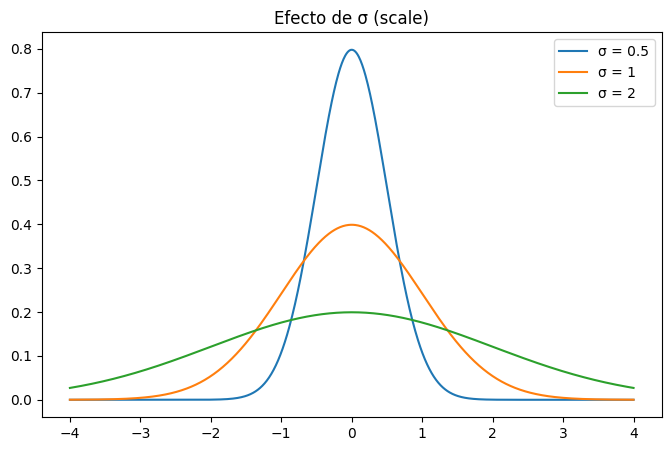

In [88]:
fig, ax = plt.subplots(figsize=(8, 5))

for sigma in [0.5, 1, 2]:
    y = stats.norm.pdf(x, loc=0, scale=sigma)
    ax.plot(x, y, label=f"σ = {sigma}")

ax.set_title("Efecto de σ (scale)")
ax.legend()
plt.show()

## Bloque 11.1 — 🎨 Galería de distribuciones con ejemplos reales

`scipy.stats` trae muchas más distribuciones además de la normal. Esta plantilla arma una
grilla de subplots con varias distribuciones **discretas y continuas**, cada una asociada a
un ejemplo de la vida real:

| Distribución | Tipo | Ejemplo real |
|---|---|---|
| Binomial | discreta | cantidad de artículos defectuosos en un lote de 20 (p=10%) |
| Poisson | discreta | llamadas que recibe un call center en un minuto (λ=3) |
| Uniforme | continua | minutos de espera de un colectivo que pasa cada 15 min |
| Exponencial | continua | minutos entre la llegada de dos clientes a un local |

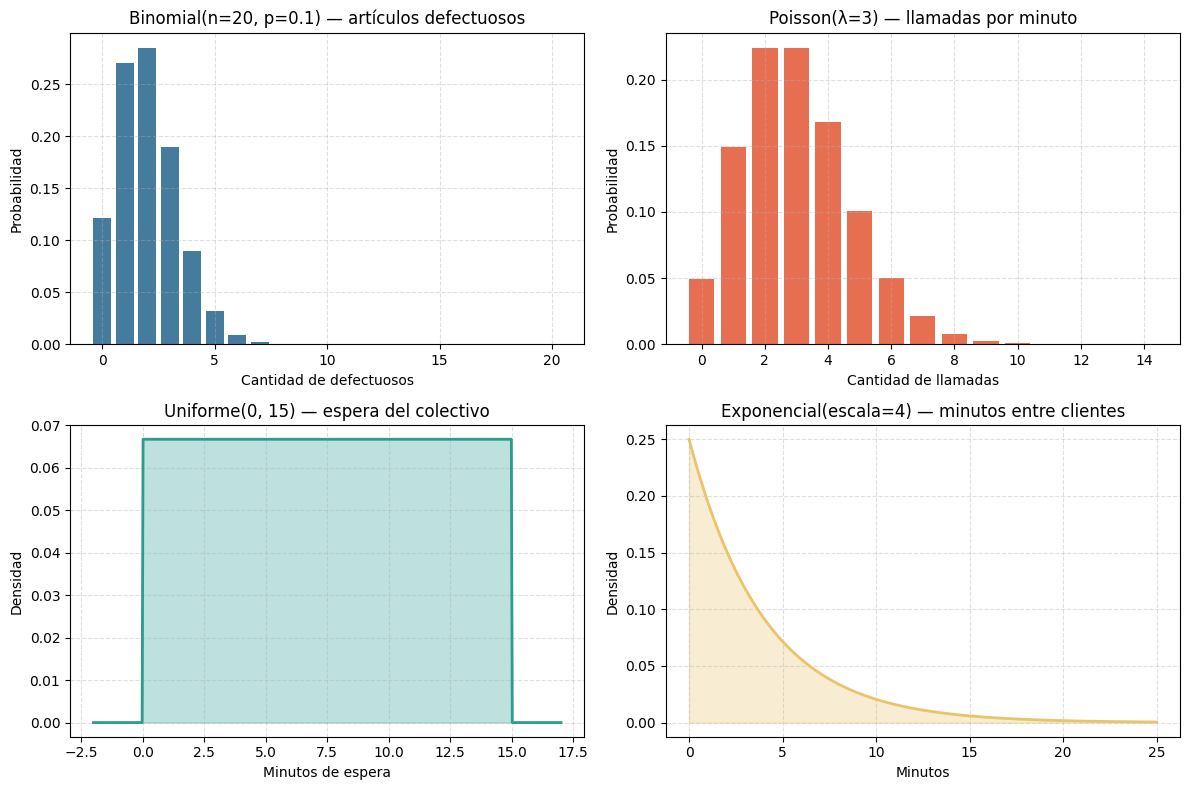

In [89]:
# ============================================
# 🎨 VARIABLES EDITABLES — cambiá los parámetros de cada distribución
# ============================================
n_binomial, p_binomial = 20, 0.10
lambda_poisson          = 3
uniforme_min, uniforme_max = 0, 15
escala_exponencial      = 4

colores = ["#457b9d", "#e76f51", "#2a9d8f", "#e9c46a"]
# ============================================

x_binomial = np.arange(0, n_binomial + 1)
y_binomial = stats.binom.pmf(x_binomial, n_binomial, p_binomial)

x_poisson = np.arange(0, 15)
y_poisson = stats.poisson.pmf(x_poisson, lambda_poisson)

x_uniforme = np.linspace(uniforme_min - 2, uniforme_max + 2, 500)
y_uniforme = stats.uniform.pdf(x_uniforme, loc=uniforme_min, scale=uniforme_max - uniforme_min)

x_exponencial = np.linspace(0, 25, 500)
y_exponencial = stats.expon.pdf(x_exponencial, scale=escala_exponencial)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].bar(x_binomial, y_binomial, color=colores[0])
axes[0, 0].set_title(f"Binomial(n={n_binomial}, p={p_binomial}) — artículos defectuosos")
axes[0, 0].set_xlabel("Cantidad de defectuosos")
axes[0, 0].set_ylabel("Probabilidad")

axes[0, 1].bar(x_poisson, y_poisson, color=colores[1])
axes[0, 1].set_title(f"Poisson(λ={lambda_poisson}) — llamadas por minuto")
axes[0, 1].set_xlabel("Cantidad de llamadas")
axes[0, 1].set_ylabel("Probabilidad")

axes[1, 0].plot(x_uniforme, y_uniforme, color=colores[2], linewidth=2)
axes[1, 0].fill_between(x_uniforme, y_uniforme, alpha=0.3, color=colores[2])
axes[1, 0].set_title(f"Uniforme({uniforme_min}, {uniforme_max}) — espera del colectivo")
axes[1, 0].set_xlabel("Minutos de espera")
axes[1, 0].set_ylabel("Densidad")

axes[1, 1].plot(x_exponencial, y_exponencial, color=colores[3], linewidth=2)
axes[1, 1].fill_between(x_exponencial, y_exponencial, alpha=0.3, color=colores[3])
axes[1, 1].set_title(f"Exponencial(escala={escala_exponencial}) — minutos entre clientes")
axes[1, 1].set_xlabel("Minutos")
axes[1, 1].set_ylabel("Densidad")

for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

✏️ **Ejercicio:**
1. Subí `p_binomial` a `0.4`. ¿Hacia dónde se corre el pico de la distribución?
2. Bajá `lambda_poisson` a `1`. ¿Qué le pasa a la probabilidad de recibir 0 llamadas?
3. Agregá una quinta distribución a la grilla (por ejemplo `stats.gamma` o una segunda
   binomial con otro `p`), cambiando `subplots(2, 2, ...)` por `subplots(3, 2, ...)`.

**Conclusión visual:**

```
μ (loc)   → posición de la campana
σ (scale) → dispersión / ancho de la campana
```

## PMF, PDF y CDF: tres formas de responder "¿qué tan probable es?"

| Tipo | Variable | Objeto | Pregunta que responde |
|---|---|---|---|
| **PMF** | Discreta | Barras | `P(X = x)` |
| **PDF** | Continua | Curva de densidad | "altura" relativa, no una probabilidad puntual |
| **CDF** | Ambas | Curva acumulada | `P(X ≤ x)` |

```
⚠️ PDF(x)  NO significa  P(X = x)
```

```
PDF
altura
   ↓
NO ES PROBABILIDAD

ÁREA ENTRE DOS VALORES
   ↓
SÍ ES PROBABILIDAD
```

Para una variable **continua**, `P(X = x)` puntual es siempre 0 — lo que sí podemos calcular es el área bajo la curva entre dos valores (lo vemos un poco más abajo). Primero, comparemos PDF y CDF lado a lado:


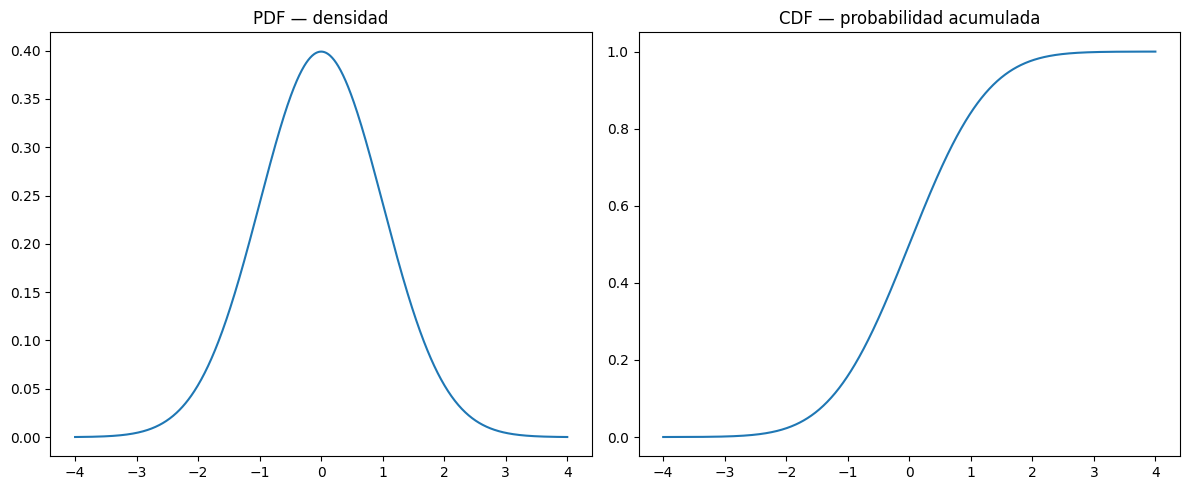

In [90]:
x = np.linspace(-4, 4, 1000)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(x, stats.norm.pdf(x))
axes[0].set_title("PDF — densidad")

axes[1].plot(x, stats.norm.cdf(x))
axes[1].set_title("CDF — probabilidad acumulada")

plt.tight_layout()
plt.show()

Para variables **discretas** usamos `pmf` en vez de `pdf`, y barras en vez de líneas.
Ejemplo: una Poisson con λ = 5.

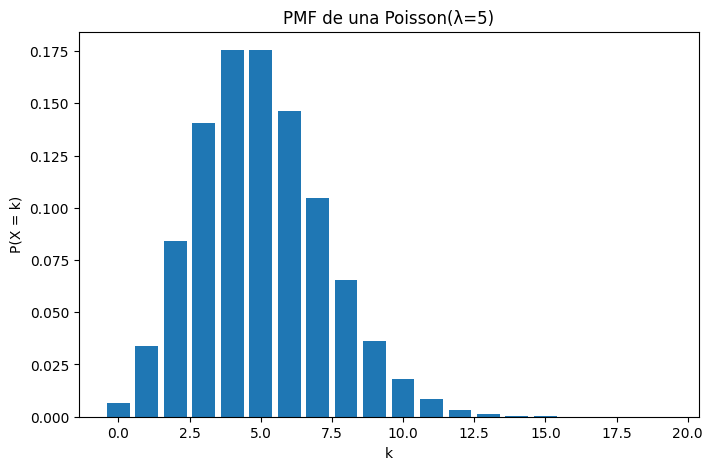

In [91]:
x_disc = np.arange(0, 20)
y_disc = stats.poisson.pmf(x_disc, mu=5)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x_disc, y_disc)
ax.set_title("PMF de una Poisson(λ=5)")
ax.set_xlabel("k")
ax.set_ylabel("P(X = k)")
plt.show()

### ✏️ Ejercicio — Comparar varias Poisson en el mismo gráfico

Usando el mismo patrón que en el Bloque 11 (loop + `label` + `legend`), superpongamos
distintos valores de λ para comparar formas.

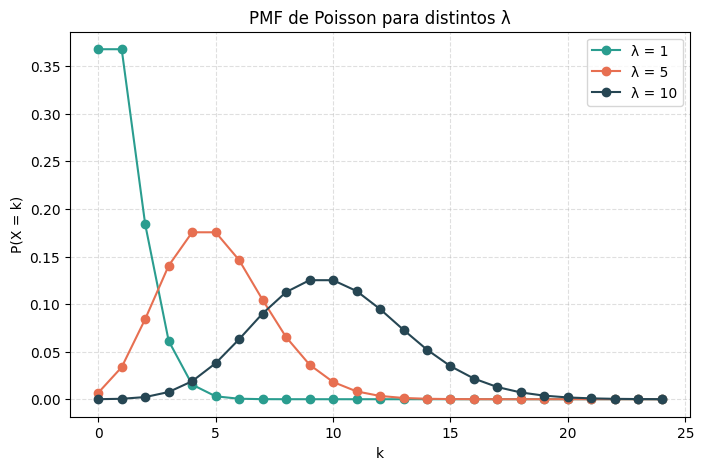

In [92]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
valores_lambda = [1, 5, 10]
colores        = ["#2a9d8f", "#e76f51", "#264653"]
x_max          = 25
# ============================================

x_disc = np.arange(0, x_max)

fig, ax = plt.subplots(figsize=(8, 5))

for lam, color in zip(valores_lambda, colores):
    y_disc = stats.poisson.pmf(x_disc, mu=lam)
    ax.plot(x_disc, y_disc, marker="o", color=color, label=f"λ = {lam}")

ax.set_title("PMF de Poisson para distintos λ")
ax.set_xlabel("k")
ax.set_ylabel("P(X = k)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.show()

✏️ **Para pensar:** a medida que λ crece, ¿la distribución se parece cada vez más a alguna
de las distribuciones continuas que vimos en el Bloque 11.1? (pista: mirá la forma cuando
λ = 10 y compará con una normal centrada en 10).

## Bloque 13 — La probabilidad como área bajo la curva

Para variables continuas, la probabilidad de que $X \leq 1$ es el **área** bajo la PDF hasta
ese punto — y eso es exactamente lo que calcula la CDF.

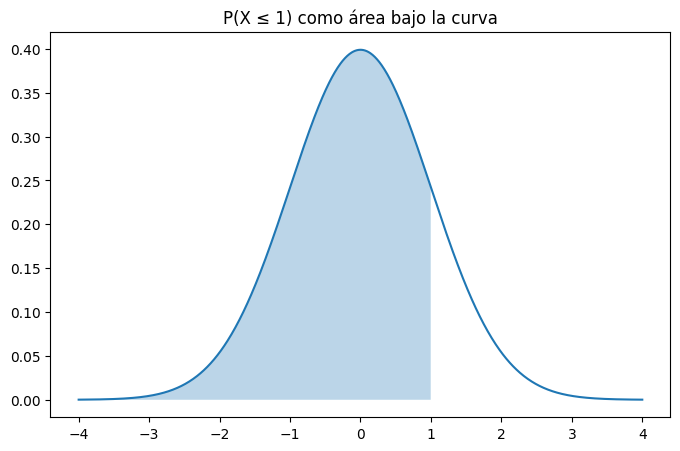

In [93]:
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, y)

mask = x <= 1
ax.fill_between(x[mask], y[mask], alpha=0.3)

ax.set_title("P(X ≤ 1) como área bajo la curva")
plt.show()

In [94]:
print("P(X <= 1) =", round(stats.norm.cdf(1), 4))

P(X <= 1) = 0.8413


### 🎨 Plantilla editable — Probabilidad entre dos valores (área bajo la curva)

Generalizamos el Bloque 13 para calcular y visualizar $P(a \leq X \leq b)$ para cualquier
distribución normal, con el valor anotado directamente sobre el gráfico.

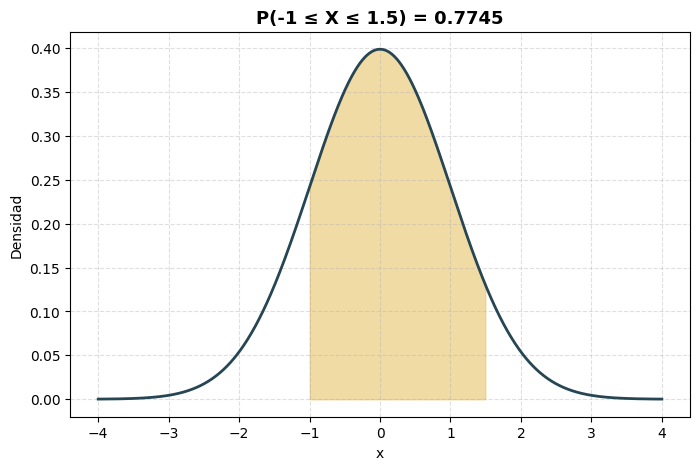

Probabilidad = 0.7745


In [95]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
media_dist  = 0
sigma_dist  = 1
limite_inf  = -1
limite_sup  = 1.5

color_curva   = "#264653"
color_relleno = "#e9c46a"
# ============================================

x = np.linspace(media_dist - 4 * sigma_dist, media_dist + 4 * sigma_dist, 1000)
y = stats.norm.pdf(x, loc=media_dist, scale=sigma_dist)

probabilidad = stats.norm.cdf(limite_sup, loc=media_dist, scale=sigma_dist) - \
               stats.norm.cdf(limite_inf, loc=media_dist, scale=sigma_dist)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, y, color=color_curva, linewidth=2)

mask = (x >= limite_inf) & (x <= limite_sup)
ax.fill_between(x[mask], y[mask], color=color_relleno, alpha=0.6)

ax.set_title(f"P({limite_inf} ≤ X ≤ {limite_sup}) = {probabilidad:.4f}", fontsize=13, fontweight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Densidad")
ax.grid(True, linestyle="--", alpha=0.4)

plt.show()

print(f"Probabilidad = {probabilidad:.4f}")

✏️ **Ejercicio:** una fábrica produce piezas cuyo diámetro sigue una normal con
`media_dist = 50` mm y `sigma_dist = 2` mm. Las piezas se aceptan si su diámetro está
entre 47 y 53 mm. Usá la plantilla para calcular qué porcentaje de piezas se rechaza
(pista: 1 - la probabilidad que calculaste).

```
ÁREA BAJO LA CURVA  =  PROBABILIDAD
```

## Bloque 14 — Simulación vs. distribución teórica

¿Qué tan bien un modelo teórico (`scipy.stats`) describe datos simulados (`rng`)? Generamos
10.000 muestras normales y las comparamos contra la curva teórica.

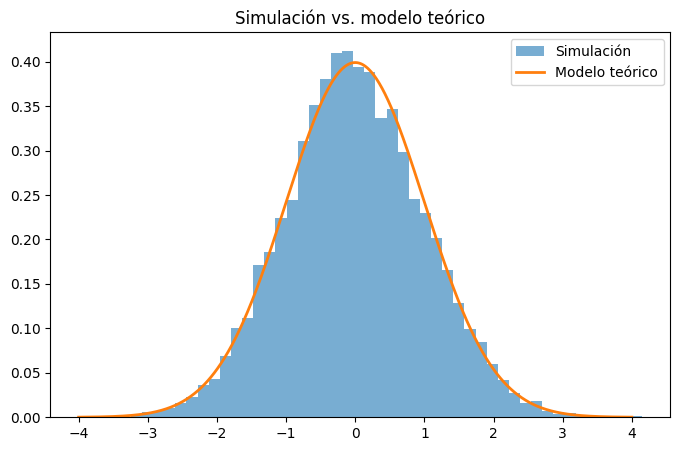

In [96]:
muestra = rng.normal(0, 1, 10000)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(muestra, bins=50, density=True, alpha=0.6, label="Simulación")

x = np.linspace(-4, 4, 1000)
ax.plot(x, stats.norm.pdf(x), label="Modelo teórico", linewidth=2)

ax.set_title("Simulación vs. modelo teórico")
ax.legend()
plt.show()

### ✏️ Ejercicio — Repetir con otra distribución

El Bloque 14 comparó una simulación normal contra su modelo teórico. Repetí el mismo
patrón (`hist(..., density=True)` + `plot(pdf)`) pero con una distribución **exponencial**.

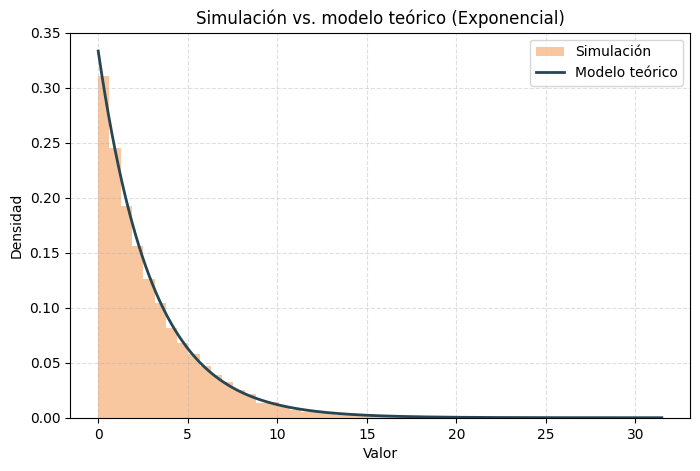

In [97]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
escala_exponencial = 3
cantidad_muestras   = 10000
color_simulacion    = "#f4a261"
color_teorico       = "#264653"
# ============================================

muestra_exp = rng.exponential(scale=escala_exponencial, size=cantidad_muestras)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(muestra_exp, bins=50, density=True, alpha=0.6, color=color_simulacion, label="Simulación")

x_exp = np.linspace(0, muestra_exp.max(), 1000)
ax.plot(x_exp, stats.expon.pdf(x_exp, scale=escala_exponencial), color=color_teorico, linewidth=2, label="Modelo teórico")

ax.set_title("Simulación vs. modelo teórico (Exponencial)")
ax.set_xlabel("Valor")
ax.set_ylabel("Densidad")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.show()

Notar el parámetro `density=True` en el histograma: convierte las frecuencias en
densidad, para que sea comparable con la PDF teórica (misma escala en el eje Y).

---
# PARTE 5 — Dos variables: ¿están relacionadas?

Ya sabemos describir **una** variable (histograma, PMF, PDF). La pregunta natural ahora es: si tengo dos variables, ¿se mueven juntas? Para eso usamos el **scatter plot**.


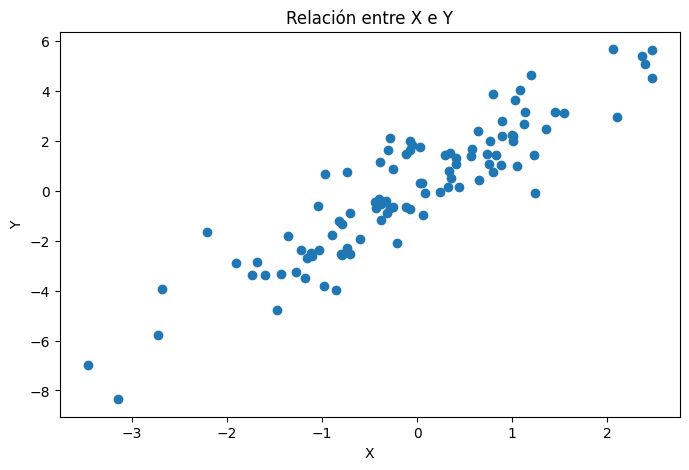

In [98]:
x = rng.normal(0, 1, 100)
y = 2 * x + rng.normal(0, 1, 100)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(x, y)

ax.set_title("Relación entre X e Y")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.show()

**Antes de calcular nada:** ¿qué patrón ven en la nube de puntos? Ahora generemos
**cuatro casos distintos** para comparar visualmente.

In [99]:
x = rng.normal(0, 1, 100)

# Caso A - Correlación positiva
y_pos = 2 * x + rng.normal(0, 1, 100)

# Caso B - Correlación negativa
y_neg = -2 * x + rng.normal(0, 1, 100)

# Caso C - Sin relación
y_sin_rel = rng.normal(0, 1, 100)

# Caso D - Relación no lineal
y_no_lineal = x ** 2 + rng.normal(0, 0.5, 100)

## Bloque 5 — Template para comparar múltiples relaciones (`subplots`)

Cuando queremos comparar varias hipótesis con la **misma escala visual**, usamos una grilla de
subplots en vez de cuatro gráficos sueltos:

```
MÚLTIPLES HIPÓTESIS → MISMA ESCALA VISUAL → COMPARACIÓN
```

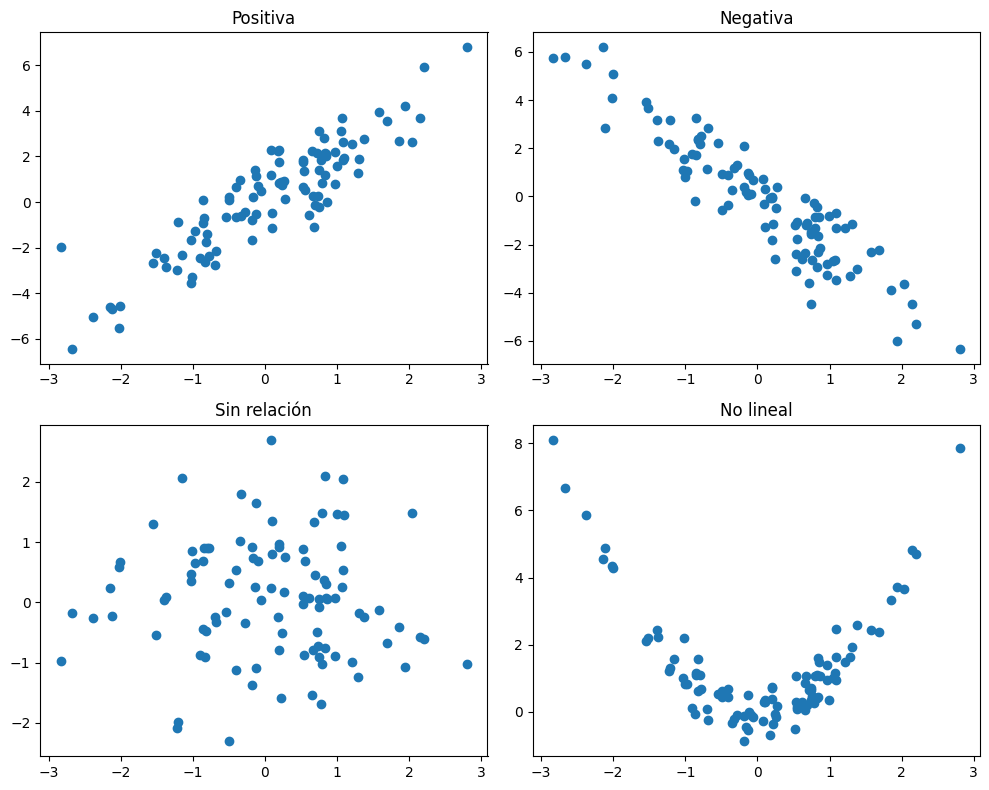

In [100]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].scatter(x, y_pos)
axes[0, 0].set_title("Positiva")

axes[0, 1].scatter(x, y_neg)
axes[0, 1].set_title("Negativa")

axes[1, 0].scatter(x, y_sin_rel)
axes[1, 0].set_title("Sin relación")

axes[1, 1].scatter(x, y_no_lineal)
axes[1, 1].set_title("No lineal")

plt.tight_layout()
plt.show()

Ahora sí, calculemos la correlación de cada caso y comparemos con lo que **vimos**:

In [101]:
print("Positiva   :", round(np.corrcoef(x, y_pos)[0, 1], 2))
print("Negativa   :", round(np.corrcoef(x, y_neg)[0, 1], 2))
print("Sin relación:", round(np.corrcoef(x, y_sin_rel)[0, 1], 2))
print("No lineal  :", round(np.corrcoef(x, y_no_lineal)[0, 1], 2))

Positiva   : 0.9
Negativa   : -0.93
Sin relación: -0.04
No lineal  : -0.14


**Idea fundamental:** la correlación (de Pearson) mide principalmente **relación lineal**.
En el caso D hay una relación clarísima (una parábola), pero la correlación puede salir baja
porque esa relación no es lineal. **Correlación no es lo mismo que dependencia.**

**Conectando con la Parte 1:** la correlación y la covarianza forman parte de lo que se llama **probabilidad conjunta** — cómo se comportan dos variables *a la vez*, en vez de cada una por separado.


## Bloque 6 — Tres variables: tamaño, color y subgrupos

Cuando tenemos una tercera variable, no podemos agregar un tercer eje en un gráfico 2D — pero
sí podemos usar **tamaño** o **color** para representarla.

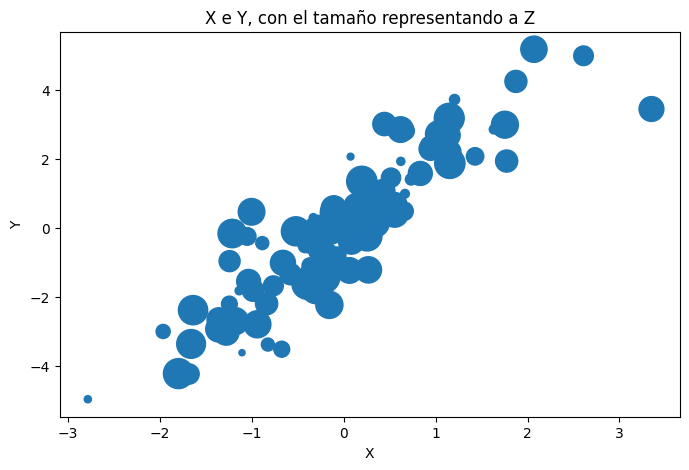

In [102]:
x = rng.normal(0, 1, 100)
y = 2 * x + rng.normal(0, 1, 100)
z = rng.uniform(20, 500, 100)   # tercera variable -> tamaño

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(x, y, s=z)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("X e Y, con el tamaño representando a Z")

plt.show()

**Estrategia 2 — tercera variable como color:**

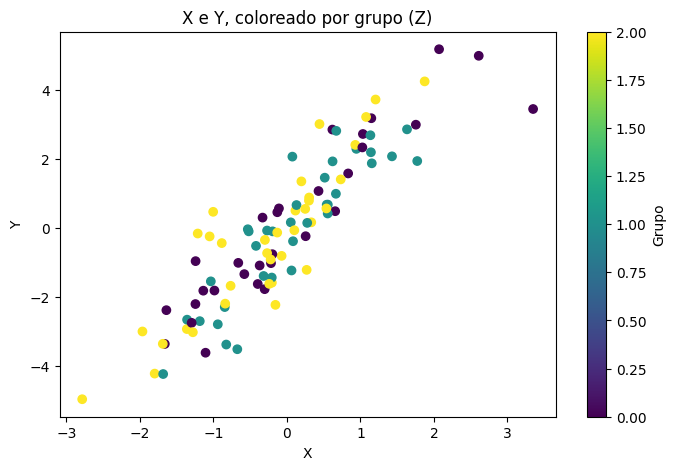

In [103]:
grupo = rng.integers(0, 3, 100)  # tercera variable -> categoría/color

fig, ax = plt.subplots(figsize=(8, 5))

scatter = ax.scatter(x, y, c=grupo)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("X e Y, coloreado por grupo (Z)")

plt.colorbar(scatter, label="Grupo")
plt.show()

**Estrategia 3 — subgrupos (con leyenda):** a veces conviene dibujar cada grupo por
separado, con su propia etiqueta.

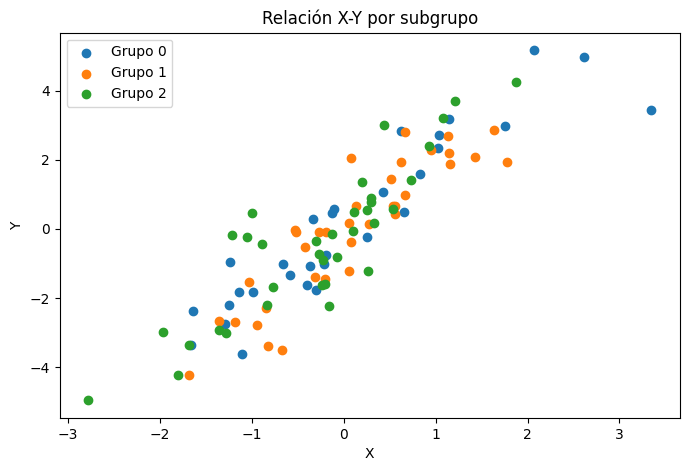

In [104]:
fig, ax = plt.subplots(figsize=(8, 5))

for grupo_actual in np.unique(grupo):
    mask = grupo == grupo_actual
    ax.scatter(x[mask], y[mask], label=f"Grupo {grupo_actual}")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Relación X-Y por subgrupo")
ax.legend()

plt.show()

### 🎨 Plantilla editable — Scatter con colores, tamaños y leyenda

Ejemplo de la vida real: horas de estudio vs. nota final de un examen, coloreado según si
el/la estudiante aprobó o no.

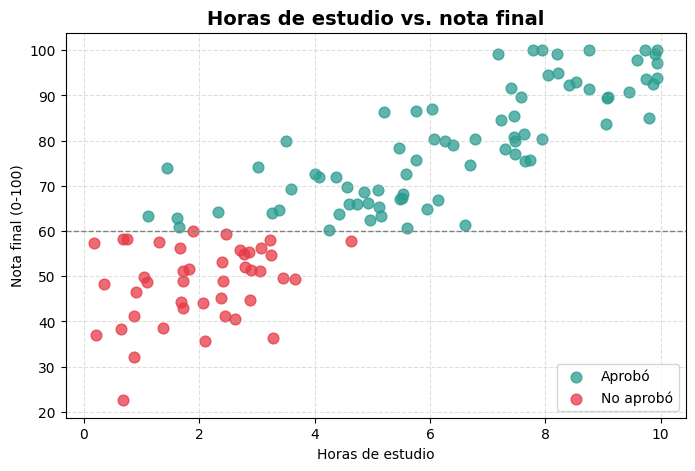

In [105]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
cantidad_estudiantes = 120
nota_para_aprobar    = 60

color_aprobado    = "#2a9d8f"
color_desaprobado = "#e63946"
tamaño_puntos     = 60
transparencia     = 0.75
marcador          = "o"

titulo     = "Horas de estudio vs. nota final"
etiqueta_x = "Horas de estudio"
etiqueta_y = "Nota final (0-100)"
ubicacion_leyenda = "lower right"   # "best", "upper left", "lower right", etc.
# ============================================

horas_estudio = rng.uniform(0, 10, cantidad_estudiantes)
nota_final = np.clip(40 + horas_estudio * 6 + rng.normal(0, 10, cantidad_estudiantes), 0, 100)
aprobo = nota_final >= nota_para_aprobar

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    horas_estudio[aprobo], nota_final[aprobo],
    color=color_aprobado, s=tamaño_puntos, alpha=transparencia,
    marker=marcador, label="Aprobó",
)
ax.scatter(
    horas_estudio[~aprobo], nota_final[~aprobo],
    color=color_desaprobado, s=tamaño_puntos, alpha=transparencia,
    marker=marcador, label="No aprobó",
)

ax.axhline(nota_para_aprobar, color="gray", linestyle="--", linewidth=1)

ax.set_title(titulo, fontsize=14, fontweight="bold")
ax.set_xlabel(etiqueta_x)
ax.set_ylabel(etiqueta_y)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc=ubicacion_leyenda)

plt.show()

✏️ **Ejercicio:**
1. Cambiá `nota_para_aprobar` a `70` y observá cómo cambia la cantidad de puntos rojos.
2. Agregá una tercera categoría "Ausente" (por ejemplo, con `nota_final = np.nan` para
   un 10% de los estudiantes) y decidí cómo representarla.
3. Probá `ubicacion_leyenda = "upper left"` y otras posiciones.

**Idea clave:** la relación global entre X e Y puede **esconder** relaciones distintas
dentro de cada subgrupo. Separar por grupo es una herramienta central de EDA.

---
# PARTE 6 — Variable categórica + variable continua: el boxplot

¿Cómo comparamos una variable continua entre distintas categorías (por ejemplo, un puntaje entre los grupos A, B y C)? El histograma superpuesto se vuelve ilegible con más de dos grupos — para eso existe el **boxplot**.


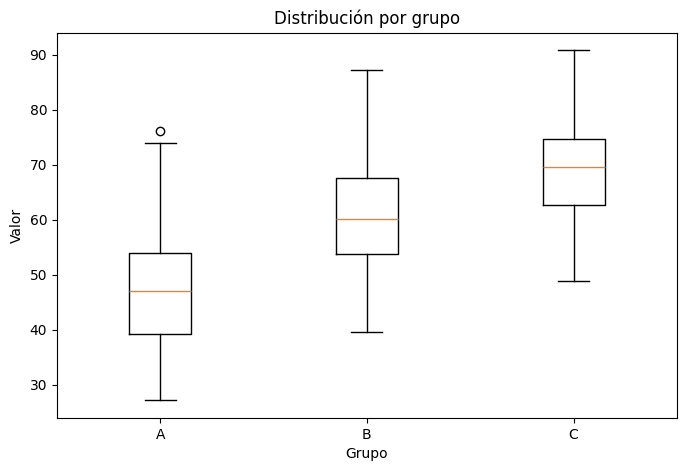

In [106]:
grupos = ["A", "B", "C"]

datos = [
    rng.normal(50, 10, 100),
    rng.normal(60, 10, 100),
    rng.normal(70, 10, 100),
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(datos, tick_labels=grupos)

ax.set_title("Distribución por grupo")
ax.set_xlabel("Grupo")
ax.set_ylabel("Valor")

plt.show()

### 🎨 Plantilla editable — Boxplot con colores por caja

Ejemplo de la vida real: tiempo de entrega (en días) de 3 proveedores distintos.

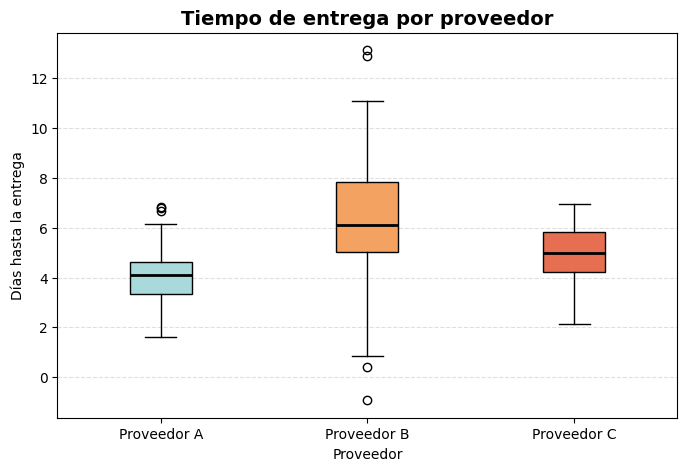

In [107]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
proveedores = ["Proveedor A", "Proveedor B", "Proveedor C"]
medias_entrega  = [4, 6, 5]
desvios_entrega = [1, 2.5, 1.2]
cantidad_pedidos = 80

colores_cajas = ["#a8dadc", "#f4a261", "#e76f51"]

titulo     = "Tiempo de entrega por proveedor"
etiqueta_x = "Proveedor"
etiqueta_y = "Días hasta la entrega"
# ============================================

datos_entrega = [
    rng.normal(m, d, cantidad_pedidos)
    for m, d in zip(medias_entrega, desvios_entrega)
]

fig, ax = plt.subplots(figsize=(8, 5))

cajas = ax.boxplot(
    datos_entrega,
    tick_labels=proveedores,
    patch_artist=True,          # necesario para poder pintar las cajas
    medianprops=dict(color="black", linewidth=2),
)

for caja, color in zip(cajas["boxes"], colores_cajas):
    caja.set_facecolor(color)

ax.set_title(titulo, fontsize=14, fontweight="bold")
ax.set_xlabel(etiqueta_x)
ax.set_ylabel(etiqueta_y)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

✏️ **Ejercicio:**
1. Cambiá `desvios_entrega` para que el Proveedor C tenga muchísima variabilidad
   (por ejemplo `desvios_entrega = [1, 2.5, 5]`) y comparalo con los otros.
2. ¿Qué proveedor elegirías si además de la mediana te importa la consistencia? Justificá
   mirando el ancho de las cajas y los bigotes.

El boxplot resume, para cada grupo:

```
CATEGORÍA + VARIABLE CONTINUA → BOXPLOT
```

- La **línea central** es la mediana.
- La **caja** va del primer al tercer cuartil (contiene el 50% central de los datos → el IQR).
- Los **bigotes** muestran el resto del rango "normal".
- Los **puntos sueltos** (si aparecen) son outliers.

Esto conecta directamente con estadística descriptiva: mediana, cuartiles, percentiles e IQR.

---
# PARTE 7 — Muchas variables a la vez: matriz de correlación

Con dos variables alcanza un scatter. ¿Y con cuatro o cinco? Ahí un scatter por par de variables deja de ser práctico — necesitamos una vista resumen: el **heatmap de correlaciones**.


In [108]:
n = 200

edad = rng.normal(30, 10, n)
experiencia = edad * 0.5 + rng.normal(0, 5, n)
salario = experiencia * 1000 + rng.normal(0, 3000, n)
horas_tv = rng.normal(3, 1, n)

df_demo = pd.DataFrame({
    "edad": edad,
    "experiencia": experiencia,
    "salario": salario,
    "horas_tv": horas_tv,
})

df_demo.head()

,edad,experiencia,salario,horas_tv
0,36.067329,21.806697,25500.519916,2.327284
1,32.025973,14.579227,11595.544100,2.321044
2,37.118488,20.074477,15238.280844,2.667432
3,24.742955,8.128372,12311.676362,2.056967
4,45.139895,22.454968,22696.524521,1.678545


In [109]:
corr = df_demo.corr()
corr

,edad,experiencia,salario,horas_tv
edad,1.000000,0.665380,0.590002,-0.072912
experiencia,0.665380,1.000000,0.910813,-0.006684
salario,0.590002,0.910813,1.000000,-0.008424
horas_tv,-0.072912,-0.006684,-0.008424,1.000000


Con 4 variables ya es difícil "leer" una tabla de correlaciones a simple vista. La
visualizamos como una imagen (sin depender de Seaborn — seguimos usando Matplotlib puro):

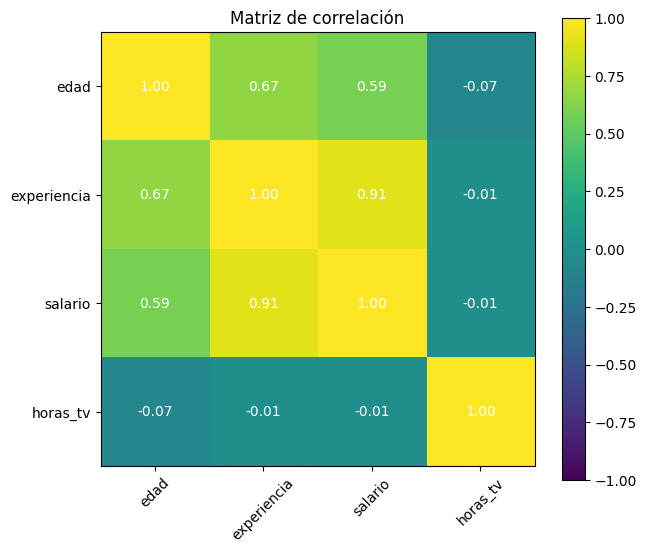

In [110]:
fig, ax = plt.subplots(figsize=(7, 6))

imagen = ax.imshow(corr, vmin=-1, vmax=1)

ax.set_xticks(np.arange(len(corr.columns)), labels=corr.columns, rotation=45)
ax.set_yticks(np.arange(len(corr.columns)), labels=corr.columns)

# Agregamos el valor numérico en cada celda
for i in range(len(corr)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="white")

ax.set_title("Matriz de correlación")
plt.colorbar(imagen)
plt.show()

### 🎨 Plantilla editable — Matriz de correlación (heatmap)

Ejemplo de la vida real: relación entre inversión en publicidad, precio, ventas y
satisfacción del cliente en una cadena de tiendas.

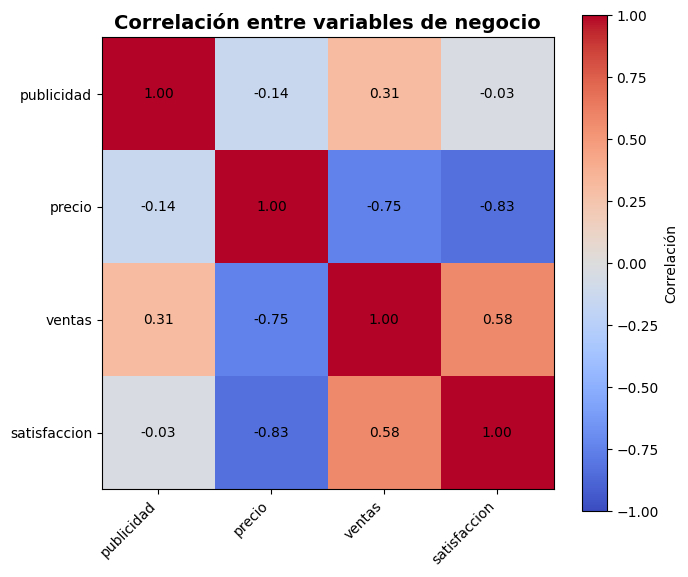

In [111]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
n_tiendas = 150

mapa_de_color   = "coolwarm"   # probá también "viridis", "RdYlGn", "plasma"
color_texto     = "black"
formato_numeros = ".2f"

titulo = "Correlación entre variables de negocio"
# ============================================

publicidad = rng.uniform(1000, 10000, n_tiendas)
precio = rng.uniform(10, 100, n_tiendas)
ventas = publicidad * 0.05 - precio * 20 + rng.normal(0, 500, n_tiendas)
satisfaccion = 100 - precio * 0.3 + rng.normal(0, 5, n_tiendas)

df_negocio = pd.DataFrame({
    "publicidad": publicidad,
    "precio": precio,
    "ventas": ventas,
    "satisfaccion": satisfaccion,
})

corr_negocio = df_negocio.corr()

fig, ax = plt.subplots(figsize=(7, 6))

imagen = ax.imshow(corr_negocio, vmin=-1, vmax=1, cmap=mapa_de_color)

ax.set_xticks(np.arange(len(corr_negocio.columns)), labels=corr_negocio.columns, rotation=45, ha="right")
ax.set_yticks(np.arange(len(corr_negocio.columns)), labels=corr_negocio.columns)

for i in range(len(corr_negocio)):
    for j in range(len(corr_negocio.columns)):
        ax.text(
            j, i, format(corr_negocio.iloc[i, j], formato_numeros),
            ha="center", va="center", color=color_texto,
        )

ax.set_title(titulo, fontsize=14, fontweight="bold")
plt.colorbar(imagen, label="Correlación")
plt.tight_layout()
plt.show()

✏️ **Ejercicio:**
1. Cambiá `mapa_de_color` a `"viridis"` y a `"RdYlGn"`. ¿Con cuál se distingue mejor una
   correlación negativa de una positiva a simple vista?
2. Agregá una quinta columna a `df_negocio` (por ejemplo `empleados`) y volvé a correr la celda.

## Bloque 8 — Tabla de referencia: ¿qué gráfico uso?

Esta tabla resume todo lo que vimos hasta ahora. Es el puente entre el **tipo de dato** y el
**tipo de gráfico**:

```
TIPO DE DATO → TIPO DE RELACIÓN → TIPO DE GRÁFICO
```

| X | Y | Visualización |
|---|---|---|
| continua | continua | scatter |
| continua | discreta | scatter / jitter |
| continua | categórica | boxplot |
| discreta | frecuencia | bar |
| categórica | frecuencia | bar |
| tiempo | continua | line |
| continua | continua + 3ra variable | scatter + tamaño/color |
| muchas continuas | muchas continuas | matriz de correlación |


---
# PARTE 8 — De describir a inferir: EDA con datasets reales

Hasta acá todos los datos fueron inventados por nosotros con `rng`. Demos el salto a datasets reales, usando **Scikit-learn únicamente como fuente de datos** (no vamos a entrenar ningún modelo de ML todavía) y aplicando exactamente las mismas herramientas que ya construimos.


In [112]:
from sklearn.datasets import load_iris

iris = load_iris()

df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris["species"] = iris.target

df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [113]:
df_iris.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [114]:
df_iris.drop(columns="species").corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


Ahora un scatter de dos variables, coloreado por especie (misma técnica del Bloque 6:
subgrupos con leyenda):

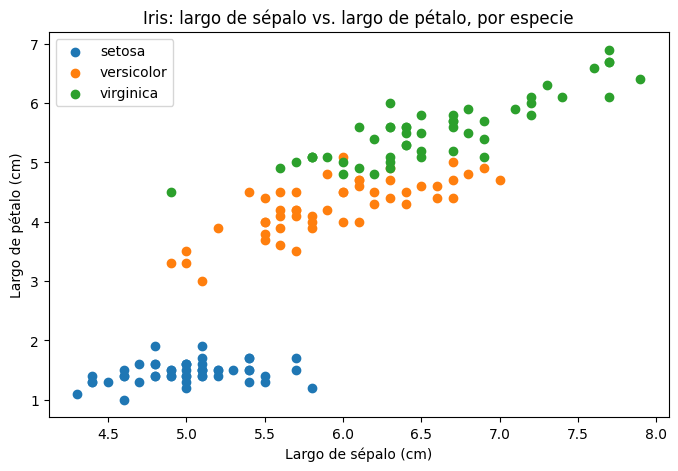

In [115]:
fig, ax = plt.subplots(figsize=(8, 5))

for especie in df_iris["species"].unique():
    subset = df_iris[df_iris["species"] == especie]
    ax.scatter(
        subset["sepal length (cm)"],
        subset["petal length (cm)"],
        label=iris.target_names[especie],
    )

ax.set_xlabel("Largo de sépalo (cm)")
ax.set_ylabel("Largo de pétalo (cm)")
ax.set_title("Iris: largo de sépalo vs. largo de pétalo, por especie")
ax.legend()

plt.show()

**Otros datasets de `sklearn.datasets` para seguir practicando:**

| Dataset | Para practicar |
|---|---|
| `load_iris` | grupos y variables continuas |
| `load_wine` | correlaciones y clasificación |
| `load_diabetes` | variables numéricas puras |
| `load_breast_cancer` | muchas variables y matriz de correlación |


In [116]:
from sklearn.datasets import load_wine, load_breast_cancer, load_diabetes

# Descomentar para explorar otros datasets:
# wine = load_wine()
# breast_cancer = load_breast_cancer()
# diabetes = load_diabetes()

---
# PARTE 9 — Población, muestra y el Teorema del Límite Central

En la práctica casi nunca tenemos **toda** la población — trabajamos con una **muestra** y queremos generalizar. Antes de ver el TLC, dejemos clara la diferencia:

```
POBLACIÓN               → todos los casos posibles
MUESTRA                 → un subconjunto que observamos
ESTADÍSTICA MUESTRAL    → un número calculado sobre la muestra (ej: la media)
```

Partimos de una población que **no es normal** (una exponencial, bien asimétrica), y vamos a ver qué pasa con las medias de muestras tomadas de ella.


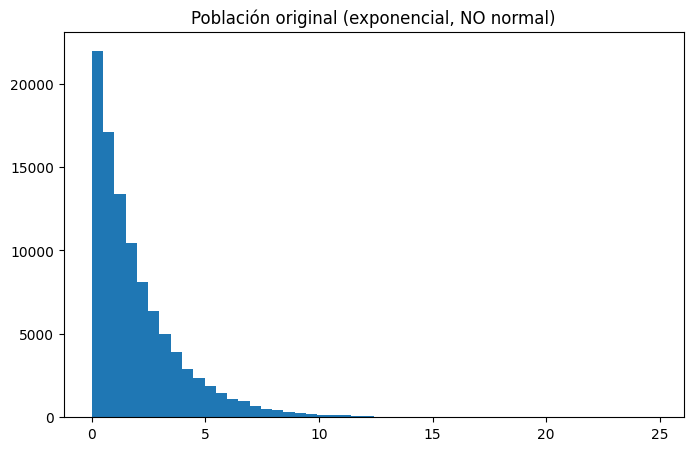

In [117]:
poblacion = rng.exponential(scale=2, size=100000)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(poblacion, bins=50)
ax.set_title("Población original (exponencial, NO normal)")
plt.show()

Ahora tomamos muchas muestras de tamaño `n`, calculamos la media de cada una, y
graficamos la distribución de esas medias muestrales:

In [118]:
def obtener_medias_muestrales(poblacion, n, repeticiones=5000):
    medias = []
    for _ in range(repeticiones):
        muestra = rng.choice(poblacion, size=n)
        medias.append(muestra.mean())
    return np.array(medias)

medias_5 = obtener_medias_muestrales(poblacion, n=5)
medias_30 = obtener_medias_muestrales(poblacion, n=30)
medias_100 = obtener_medias_muestrales(poblacion, n=100)

**Antes de correr la próxima celda:** ¿creés que la población tiene que ser normal para que las medias de las muestras se acerquen a una distribución normal? Anotá tu predicción — vamos a comprobarla con `n = 5`, `n = 30` y `n = 100`.


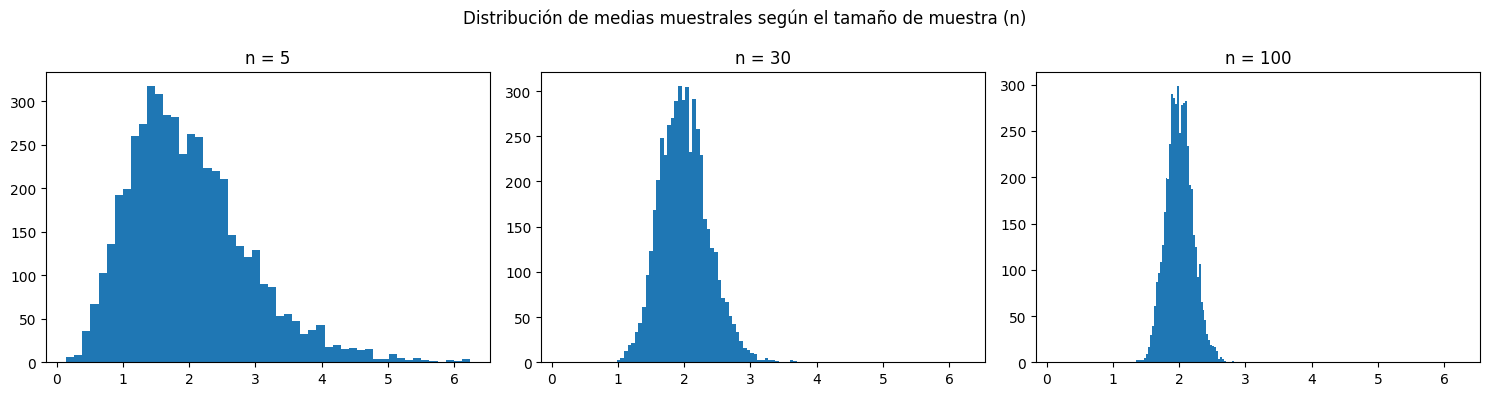

In [119]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

axes[0].hist(medias_5, bins=50)
axes[0].set_title("n = 5")

axes[1].hist(medias_30, bins=50)
axes[1].set_title("n = 30")

axes[2].hist(medias_100, bins=50)
axes[2].set_title("n = 100")

fig.suptitle("Distribución de medias muestrales según el tamaño de muestra (n)")
plt.tight_layout()
plt.show()

### ✏️ Ejercicio — TLC partiendo de otra población

El Bloque 15 partió de una población exponencial (muy asimétrica). Repetí el experimento
completo (población → medias muestrales para varios `n` → histogramas) partiendo de una
población **uniforme** (por ejemplo `rng.uniform(0, 10, 100000)`), que tiene una forma
totalmente distinta (plana, sin cola). ¿El resultado final (que las medias se parecen a una
normal) se sigue cumpliendo?

Reutilizá la función `obtener_medias_muestrales` que ya está definida más arriba — no hace
falta reescribirla.

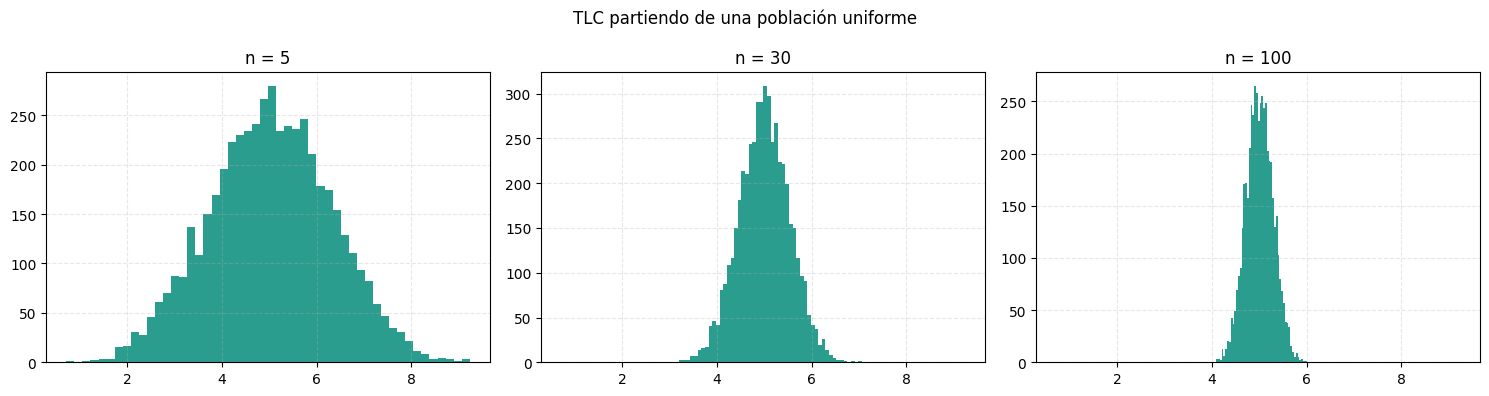

In [120]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
poblacion_uniforme = rng.uniform(0, 10, 100000)
tamaños_de_muestra = [5, 30, 100]
color_histograma   = "#2a9d8f"
# ============================================

fig, axes = plt.subplots(1, len(tamaños_de_muestra), figsize=(5 * len(tamaños_de_muestra), 4), sharex=True)

for ax, n in zip(axes, tamaños_de_muestra):
    medias = obtener_medias_muestrales(poblacion_uniforme, n=n)
    ax.hist(medias, bins=50, color=color_histograma)
    ax.set_title(f"n = {n}")
    ax.grid(True, linestyle="--", alpha=0.3)

fig.suptitle("TLC partiendo de una población uniforme")
plt.tight_layout()
plt.show()

**Lo que deberían ver:** a medida que `n` crece, la distribución de las medias muestrales
se parece cada vez más a una **normal** — aunque la población original (exponencial) no lo era.
Ese es el Teorema del Límite Central, y es la base que justifica usar distribuciones muestrales
normales en inferencia estadística.

```
Población original (exponencial)
       ≠
Distribución de los datos individuales
       ≠
Distribución de las medias muestrales (cada vez más normal a medida que crece n)
```

Esta distinción es la base de casi toda la inferencia estadística: no importa qué forma tenga la población, las medias de sus muestras tienden a una normal. Eso es lo que nos permite construir los intervalos de confianza de la próxima parte.


---
# PARTE 10 — Estimación e intervalos de confianza

Si solo tenemos una muestra de notas de examen, ¿qué podemos decir sobre el promedio de **todos** los estudiantes (la población)?

```
ESTIMACIÓN PUNTUAL          vs.          INTERVALO DE CONFIANZA
"la media muestral es 71.2"              "la media poblacional está,
                                          con 95% de confianza,
                                          entre 68.5 y 73.9"
```

Un intervalo de confianza del 95% **no significa** "hay 95% de probabilidad de que la media poblacional esté en este intervalo". Significa que **si repitiéramos el proceso de tomar una muestra y construir el intervalo muchas veces**, aproximadamente el 95% de esos intervalos contendrían a la media poblacional real.

Construyamos uno a partir de una muestra de 40 notas de examen:


Media muestral        : 71.10
Intervalo de confianza: [67.85, 74.36]


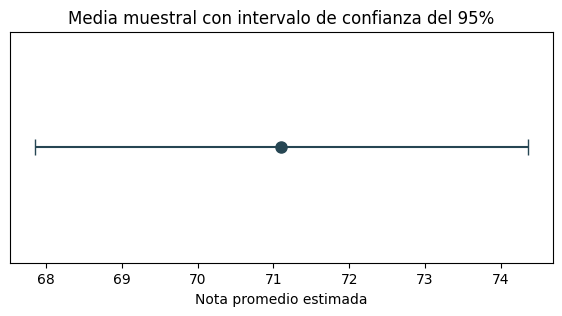

In [121]:
muestra_notas = rng.normal(loc=71, scale=9, size=40)

media_muestral = muestra_notas.mean()
error_estandar = stats.sem(muestra_notas)  # desvío estándar de la media muestral

nivel_confianza = 0.95
ic_inferior, ic_superior = stats.t.interval(
    nivel_confianza,
    df=len(muestra_notas) - 1,
    loc=media_muestral,
    scale=error_estandar,
)

print(f"Media muestral        : {media_muestral:.2f}")
print(f"Intervalo de confianza: [{ic_inferior:.2f}, {ic_superior:.2f}]")

fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(
    media_muestral, 0,
    xerr=[[media_muestral - ic_inferior], [ic_superior - media_muestral]],
    fmt="o", color="#264653", capsize=6, markersize=8,
)
ax.set_yticks([])
ax.set_xlabel("Nota promedio estimada")
ax.set_title(f"Media muestral con intervalo de confianza del {int(nivel_confianza*100)}%")
plt.show()


✏️ **Ejercicio:** repetí la celda anterior con `size=200` en vez de `size=40` (una muestra más grande) y compará el ancho del intervalo. ¿Qué relación hay entre el tamaño de la muestra y la precisión de la estimación?


---
# PARTE 11 — Introducción a pruebas de hipótesis

Otra pregunta típica: ¿la evidencia que tenemos alcanza para afirmar algo sobre la población, o podría deberse simplemente al azar del muestreo?

```
Pregunta
    ↓
H₀ (hipótesis nula, "no hay efecto / no hay diferencia")
    ↓
H₁ (hipótesis alternativa, lo que queremos evidenciar)
    ↓
Muestra
    ↓
Estadístico de prueba
    ↓
p-value
    ↓
¿Hay evidencia suficiente contra H₀?
```

**Ejemplo:** un curso histórico rindió con promedio 70. Este año, una muestra de 35 estudiantes tuvo un promedio distinto. ¿Es una diferencia real o puede explicarse por variación muestral? Usamos una prueba t de una muestra:

- H₀: la media del curso este año es 70.
- H₁: la media del curso este año es distinta de 70.


In [122]:
media_historica = 70
muestra_este_año = rng.normal(loc=74, scale=10, size=35)

estadistico_t, p_value = stats.ttest_1samp(muestra_este_año, popmean=media_historica)

alfa = 0.05
print(f"Media de la muestra : {muestra_este_año.mean():.2f}")
print(f"Estadístico t       : {estadistico_t:.3f}")
print(f"p-value             : {p_value:.4f}")

if p_value < alfa:
    print(f"p-value < {alfa} → rechazamos H₀: hay evidencia de que la media cambió.")
else:
    print(f"p-value >= {alfa} → no hay evidencia suficiente para rechazar H₀.")


Media de la muestra : 74.33
Estadístico t       : 2.520
p-value             : 0.0166
p-value < 0.05 → rechazamos H₀: hay evidencia de que la media cambió.


✏️ **Ejercicio:** cambiá `loc=74` por `loc=71` en la simulación de `muestra_este_año` (una diferencia mucho más chica frente al histórico) y volvé a correr la celda. ¿Cambia la conclusión? Esto muestra que el p-value depende tanto del **tamaño del efecto** como del **tamaño de la muestra**.


---
# PARTE 12 — Laboratorio integrador: EDA + probabilidad sobre un dataset real

Cerramos uniendo todo lo que construimos: cargamos un dataset real con Scikit-learn y aplicamos el pipeline completo (describir → visualizar una variable → comparar entre grupos → correlaciones → formular hipótesis).


In [123]:
from sklearn.datasets import load_wine

wine = load_wine()

df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
df_wine["target"] = wine.target

# 1-2-3: cargar, identificar, describir
df_wine.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


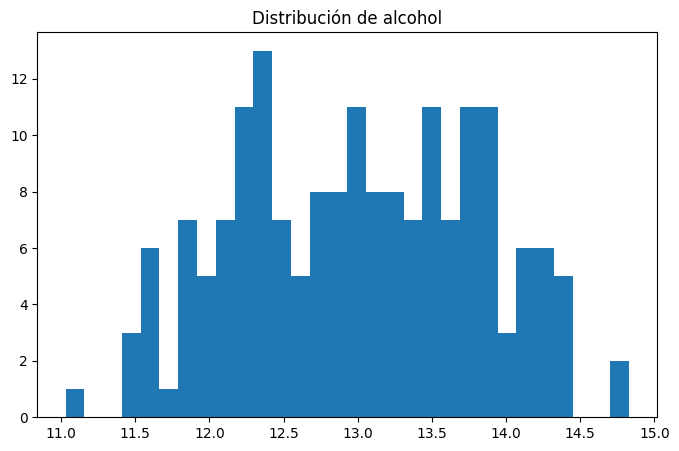

In [124]:
# 4: visualizar distribución de una variable continua (Bloque 2)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df_wine["alcohol"], bins=30)
ax.set_title("Distribución de alcohol")
plt.show()

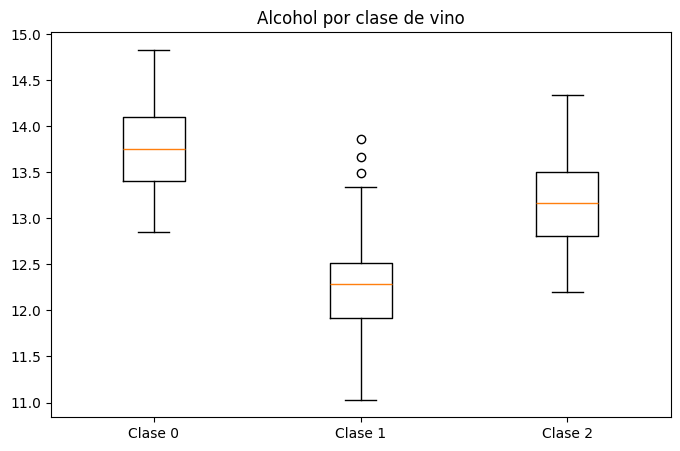

In [125]:
# 6: comparar una variable continua entre grupos (Bloque 7 - boxplot)
grupos_wine = [df_wine[df_wine["target"] == g]["alcohol"] for g in df_wine["target"].unique()]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(grupos_wine, tick_labels=[f"Clase {g}" for g in df_wine["target"].unique()])
ax.set_title("Alcohol por clase de vino")
plt.show()

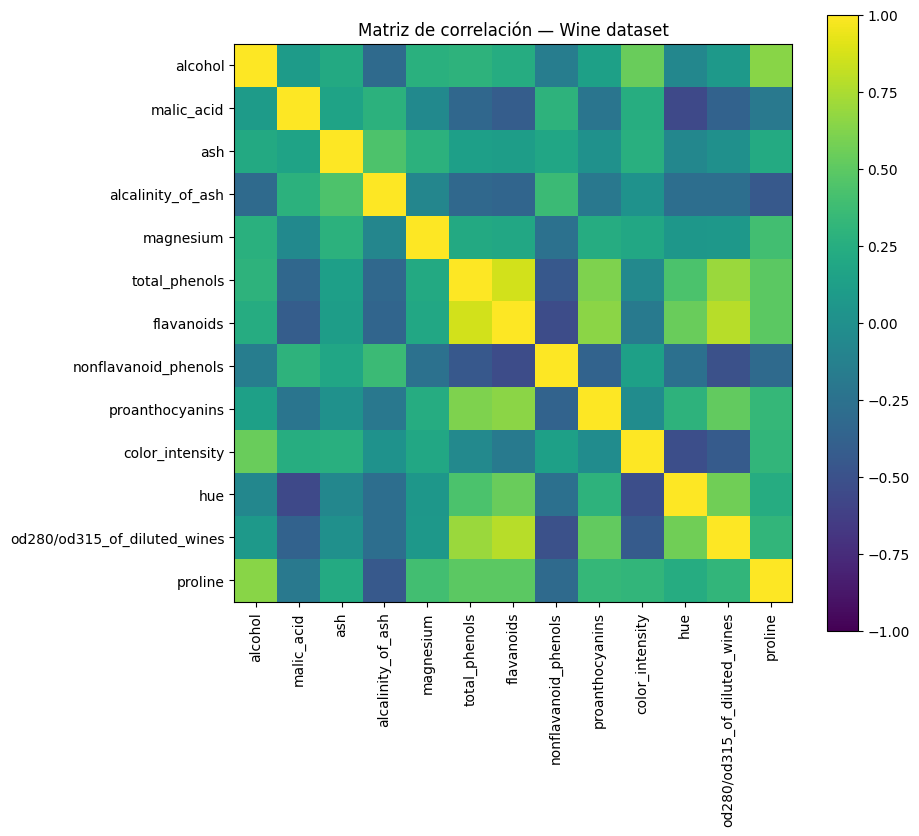

In [126]:
# 7: correlaciones (Bloque 9)
corr_wine = df_wine.drop(columns="target").corr()

fig, ax = plt.subplots(figsize=(9, 8))
imagen = ax.imshow(corr_wine, vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(corr_wine.columns)), labels=corr_wine.columns, rotation=90)
ax.set_yticks(np.arange(len(corr_wine.columns)), labels=corr_wine.columns)
plt.colorbar(imagen)
ax.set_title("Matriz de correlación — Wine dataset")
plt.show()

**Formular hipótesis:** con lo que vieron en los gráficos anteriores, ¿qué par de variables parece tener mayor correlación? ¿Las clases se separan bien según el nivel de alcohol, o se superponen? Con las herramientas de las Partes 10 y 11 (intervalos de confianza y pruebas de hipótesis) ya podrían **probar formalmente** estas ideas y no solo formularlas a partir de lo que ven.


## Bloque 17 — ✏️ Mini-proyecto final: elegí tu propio dataset

Ahora te toca reproducir el pipeline completo del Bloque 16, pero con otro dataset de
`sklearn.datasets`. Te dejamos el esqueleto con los pasos y algunas plantillas de las que
usamos en todo el Colab — completá los `# TODO` con tus propias variables de color,
etiquetas y grilla.

**Datasets sugeridos:** `load_breast_cancer()` (30 variables, 2 clases) o `load_diabetes()`
(variables numéricas puras, sin clases — en ese caso salteá los pasos que comparan por grupo).

In [127]:
from sklearn.datasets import load_breast_cancer

# 1) CARGAR
datos = load_breast_cancer()
df_proyecto = pd.DataFrame(datos.data, columns=datos.feature_names)
df_proyecto["target"] = datos.target
# 2) IDENTIFICAR VARIABLES
df_proyecto.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [128]:
# 3) DESCRIBIR
df_proyecto.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


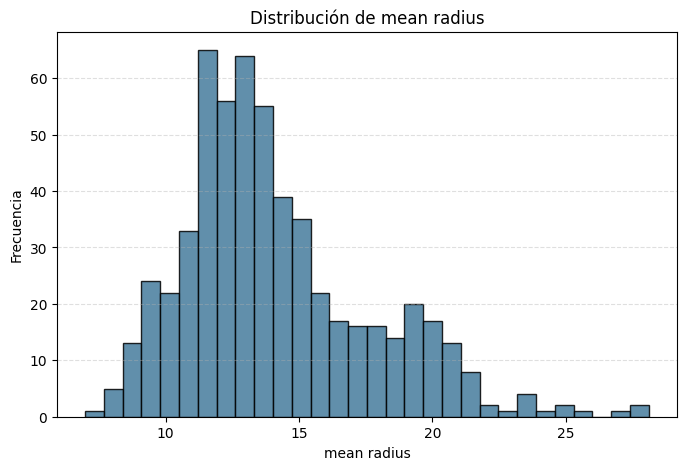

In [129]:
# 4) VISUALIZAR LA DISTRIBUCIÓN DE UNA VARIABLE CONTINUA (elegí una columna)
# ============================================
# 🎨 TODO: completá las variables editables
# ============================================
columna_elegida = "mean radius"   # TODO: probá con otras columnas de df_proyecto.columns
color_barras    = "#457b9d"       # TODO
cantidad_bins   = 30               # TODO
# ============================================

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df_proyecto[columna_elegida], bins=cantidad_bins, color=color_barras, edgecolor="black", alpha=0.85)
ax.set_title(f"Distribución de {columna_elegida}")      # TODO: personalizá el título
ax.set_xlabel(columna_elegida)
ax.set_ylabel("Frecuencia")
ax.grid(axis="y", linestyle="--", alpha=0.4)             # TODO: probá otro estilo de grilla
plt.show()

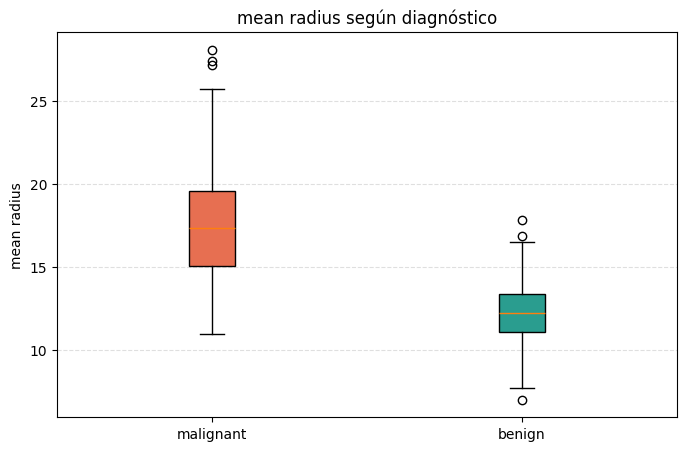

In [130]:
# 6) COMPARAR LA VARIABLE ELEGIDA ENTRE LAS DOS CLASES (boxplot, patrón del Bloque 7)
# ============================================
# 🎨 TODO: completá las variables editables
# ============================================
colores_cajas = ["#e76f51", "#2a9d8f"]   # TODO: uno por clase
# ============================================

grupos_proyecto = [
    df_proyecto[df_proyecto["target"] == g][columna_elegida]
    for g in sorted(df_proyecto["target"].unique())
]

fig, ax = plt.subplots(figsize=(8, 5))
cajas = ax.boxplot(
    grupos_proyecto,
    tick_labels=[datos.target_names[g] for g in sorted(df_proyecto["target"].unique())],
    patch_artist=True,
)
for caja, color in zip(cajas["boxes"], colores_cajas):
    caja.set_facecolor(color)

ax.set_title(f"{columna_elegida} según diagnóstico")   # TODO
ax.set_ylabel(columna_elegida)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

✏️ **Para cerrar el mini-proyecto:** agregá una celda más con la matriz de correlación de
4 o 5 columnas de `df_proyecto` (reutilizá la plantilla del Bloque 9.1) y escribí, en una
celda de texto, qué par de variables parece más relacionado con el diagnóstico.

---
## Cierre: el mapa completo

```
TENEMOS INCERTIDUMBRE
        ↓
LA MODELAMOS CON PROBABILIDAD (experimento, espacio muestral, evento)
        ↓
LA CONVERTIMOS EN UN NÚMERO (variable aleatoria)
        ↓
IDENTIFICAMOS UNA DISTRIBUCIÓN (PMF / PDF / CDF)
        ↓
VISUALIZAMOS DATOS (1, 2 o más variables)
        ↓
TOMAMOS MUESTRAS Y APLICAMOS EL TLC
        ↓
CUANTIFICAMOS INCERTIDUMBRE (intervalos de confianza)
        ↓
SACAMOS CONCLUSIONES (pruebas de hipótesis)
```

Y el rol de cada librería en todo el recorrido:

| Librería | Rol en este Colab |
|---|---|
| **Matplotlib** | El lenguaje visual: todos los gráficos, siempre con el mismo template |
| **Scikit-learn** | Solo como fuente de datasets reales (`sklearn.datasets`) para practicar EDA |
| **SciPy (`stats`)** | Modelos de probabilidad, PDF/PMF/CDF, TLC, intervalos y pruebas de hipótesis |

Quedan como **Anexos**, para consultar cuando los necesiten, el catálogo de estilos de Matplotlib y el bonus de pronóstico de series de tiempo con Prophet.


---
# ANEXO A — 🎨 Catálogo de plantillas de Matplotlib

Esto no es parte del hilo conceptual de probabilidad y estadística — es una **referencia de estilo** para consultar cuando quieran personalizar cualquiera de los gráficos anteriores (colores, marcadores, grillas, tamaños de figura).


## Bloque 1.1 — 🎨 Caja de herramientas: colores, etiquetas y grillas

Antes de seguir, este es el **catálogo de opciones** que vamos a reutilizar en todo el Colab.
No hace falta memorizarlo — quedate con la idea de que existen y volvé acá cuando lo necesites.

| Qué querés cambiar | Parámetro | Ejemplos de valores |
|---|---|---|
| Color de línea/relleno | `color` | `"crimson"`, `"#1f77b4"`, `"tab:orange"` |
| Colores por categoría (varios) | `c=[...]` o lista en `color=[...]` | `["#e63946", "#2a9d8f", "#e9c46a"]` |
| Mapa de colores continuo | `cmap` | `"viridis"`, `"coolwarm"`, `"plasma"` |
| Estilo de línea | `linestyle` | `"-"`, `"--"`, `"-."`, `":"` |
| Grosor de línea | `linewidth` | `1`, `2.5`, `4` |
| Forma del marcador | `marker` | `"o"`, `"s"`, `"^"`, `"D"`, `"x"` |
| Transparencia | `alpha` | de `0` (invisible) a `1` (opaco) |
| Grilla: on/off | `ax.grid(True/False)` | — |
| Grilla: estilo | `linestyle=` dentro de `ax.grid()` | `"--"`, `":"` |
| Grilla: solo un eje | `axis=` dentro de `ax.grid()` | `"x"`, `"y"`, `"both"` |
| Ubicación de la leyenda | `loc` en `ax.legend()` | `"best"`, `"upper right"`, `"lower left"` |
| Tamaño de la figura | `figsize=(ancho, alto)` en `plt.subplots()` | `(8, 5)`, `(12, 4)` |

La plantilla de abajo junta **todo** esto en un solo lugar. Cambiá las variables del bloque
`VARIABLES EDITABLES` y volvé a correr la celda.

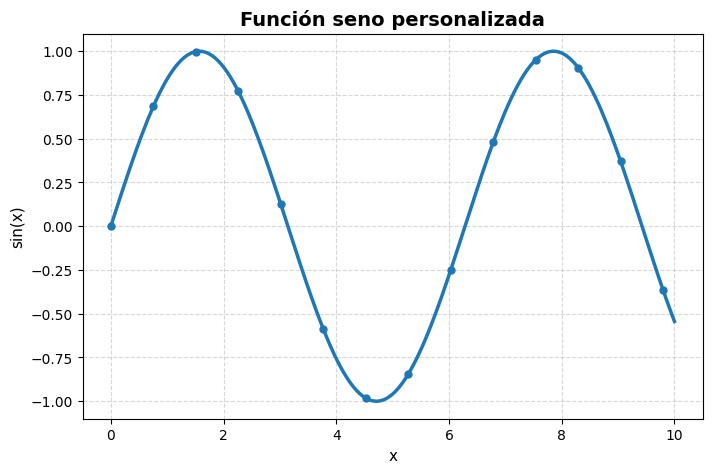

In [131]:
# ============================================
# 🎨 PLANTILLA MAESTRA — cambiá estas variables y volvé a correr la celda
# ============================================
color_linea      = "#1f77b4"   # nombre ("crimson"), hex ("#ff5733") o "tab:green"
estilo_linea     = "-"         # "-", "--", "-.", ":"
ancho_linea      = 2.5
marcador         = "o"         # "o", "s", "^", "D", "x", None (sin marcador)
tamaño_marcador  = 5
cada_cuantos_puntos_marcar = 15  # para no saturar la curva de marcadores

titulo     = "Función seno personalizada"
etiqueta_x = "x"
etiqueta_y = "sin(x)"

mostrar_grilla       = True
estilo_grilla        = "--"
transparencia_grilla = 0.5
eje_de_la_grilla     = "both"   # "x", "y" o "both"

figura_ancho, figura_alto = 8, 5
# ============================================

x = np.linspace(0, 10, 200)
y = np.sin(x)

fig, ax = plt.subplots(figsize=(figura_ancho, figura_alto))

ax.plot(
    x, y,
    color=color_linea,
    linestyle=estilo_linea,
    linewidth=ancho_linea,
    marker=marcador,
    markersize=tamaño_marcador,
    markevery=cada_cuantos_puntos_marcar,
)

ax.set_title(titulo, fontsize=14, fontweight="bold")
ax.set_xlabel(etiqueta_x, fontsize=11)
ax.set_ylabel(etiqueta_y, fontsize=11)

if mostrar_grilla:
    ax.grid(True, linestyle=estilo_grilla, alpha=transparencia_grilla, axis=eje_de_la_grilla)

plt.show()

✏️ **Ejercicio rápido:** probá, una por una, estas modificaciones sobre la celda de arriba:
1. Cambiá `color_linea` a `"crimson"` y `marcador` a `None`.
2. Poné `mostrar_grilla = False` y compará qué tan fácil es leer el gráfico sin grilla.
3. Cambiá `eje_de_la_grilla` a `"y"` y observá qué líneas desaparecen.
4. Reemplazá `np.sin(x)` por `np.cos(x)` y actualizá `etiqueta_y` y `titulo` para que tengan sentido.

**Para pensar:** de acá en adelante, cada vez que veamos un gráfico nuevo, va a ser el
mismo template con una sola línea distinta. Lo que cambia es el **tipo de gráfico**, no la
estructura.

---
# ANEXO B — 🔮 Bonus: pronóstico de series de tiempo con Prophet

Esto es un anexo optativo, no parte central de la unidad de Probabilidad y Estadística — es prácticamente otra unidad (otro modelo, entrenamiento, forecasting). Todo lo que graficamos en el resto del Colab describe datos que **ya existen**. `Prophet` (una librería de Meta para pronosticar series de tiempo) lleva la misma idea de "probabilidad como área bajo la curva" (Parte 4) hacia el **futuro**: además de predecir un valor (`yhat`), devuelve un intervalo (`yhat_lower`, `yhat_upper`) — la misma lógica de $P(a \leq X \leq b)$, pero aplicada a una fecha que todavía no pasó.

Prophet no viene instalado en Colab por defecto — corré la siguiente celda una sola vez (tarda alrededor de un minuto):


In [132]:
!pip install prophet -q

In [133]:
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)  # silencia mensajes internos de Prophet

from prophet import Prophet

print("Prophet listo ✅")

Prophet listo ✅


### 🎨 Plantilla editable — Pronóstico con banda de incertidumbre

Ejemplo de la vida real: ventas diarias de un local con tendencia creciente y estacionalidad
anual. Prophet necesita un DataFrame con dos columnas fijas: `ds` (fecha) e `y` (el valor a
pronosticar).

In [134]:
# ============================================
# 🎨 VARIABLES EDITABLES — datos simulados
# ============================================
cantidad_dias_historicos = 800
pendiente_tendencia      = 0.05     # cuánto crece por día, en promedio
amplitud_estacional      = 8        # tamaño del vaivén anual
ruido                    = 2
# ============================================

fechas = pd.date_range("2022-01-01", periods=cantidad_dias_historicos, freq="D")
tendencia = pendiente_tendencia * np.arange(len(fechas))
estacionalidad_anual = amplitud_estacional * np.sin(2 * np.pi * np.arange(len(fechas)) / 365.25)
ventas = 50 + tendencia + estacionalidad_anual + rng.normal(0, ruido, len(fechas))

df_prophet = pd.DataFrame({"ds": fechas, "y": ventas})
df_prophet.head()

,ds,y
0,2022-01-01,51.178025
1,2022-01-02,50.231275
2,2022-01-03,50.985434
3,2022-01-04,50.044974
4,2022-01-05,56.485946


In [135]:
# Entrenamos el modelo (esto reemplaza al "rng" / "stats.dist" que usábamos antes:
# acá el modelo es el que aprende la forma de los datos)
modelo = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
modelo.fit(df_prophet)

dias_a_pronosticar = 120
futuro = modelo.make_future_dataframe(periods=dias_a_pronosticar)
pronostico = modelo.predict(futuro)

pronostico[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

,ds,yhat,yhat_lower,yhat_upper
915,2024-07-04,95.618539,93.122079,98.150558
916,2024-07-05,95.501510,93.025178,97.950310
917,2024-07-06,95.387224,92.860609,98.011185
918,2024-07-07,95.276099,92.845180,97.732606
919,2024-07-08,95.168492,92.475009,97.634671


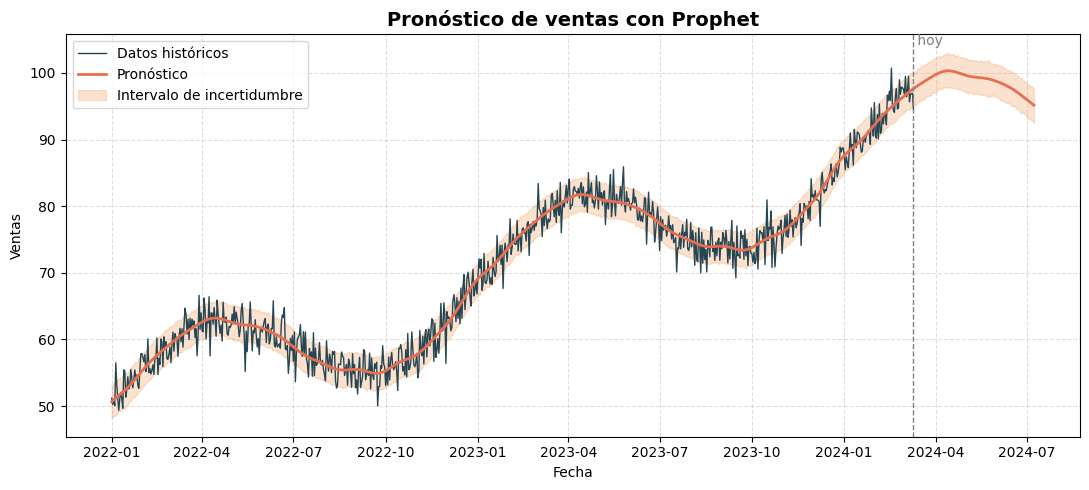

In [136]:
# ============================================
# 🎨 VARIABLES EDITABLES — estilo del gráfico
# ============================================
color_historico  = "#264653"
color_pronostico = "#e76f51"
color_banda      = "#f4a261"
alpha_banda      = 0.3

titulo     = "Pronóstico de ventas con Prophet"
etiqueta_x = "Fecha"
etiqueta_y = "Ventas"
# ============================================

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(df_prophet["ds"], df_prophet["y"], color=color_historico, linewidth=1, label="Datos históricos")
ax.plot(pronostico["ds"], pronostico["yhat"], color=color_pronostico, linewidth=2, label="Pronóstico")
ax.fill_between(
    pronostico["ds"], pronostico["yhat_lower"], pronostico["yhat_upper"],
    color=color_banda, alpha=alpha_banda, label="Intervalo de incertidumbre",
)

fecha_de_corte = df_prophet["ds"].max()
ax.axvline(fecha_de_corte, color="gray", linestyle="--", linewidth=1)
ax.text(fecha_de_corte, ax.get_ylim()[1], " hoy", va="top", color="gray")

ax.set_title(titulo, fontsize=14, fontweight="bold")
ax.set_xlabel(etiqueta_x)
ax.set_ylabel(etiqueta_y)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

✏️ **Ejercicio:**
1. Subí `ruido` a `8` y volvé a correr todo el bloque. ¿Qué le pasa al ancho de la banda de
   incertidumbre (`yhat_lower` a `yhat_upper`)?
2. Cambiá `dias_a_pronosticar` a `365`. ¿La banda se mantiene igual de angosta a medida que
   nos alejamos del último dato real, o crece?

### 🎨 Plantilla editable — Descomponer el pronóstico en sus partes

Prophet separa el pronóstico en **componentes**: tendencia + estacionalidad(es). Podemos
graficar cada una por separado con el mismo patrón de siempre (`fig, axes = plt.subplots(...)`).

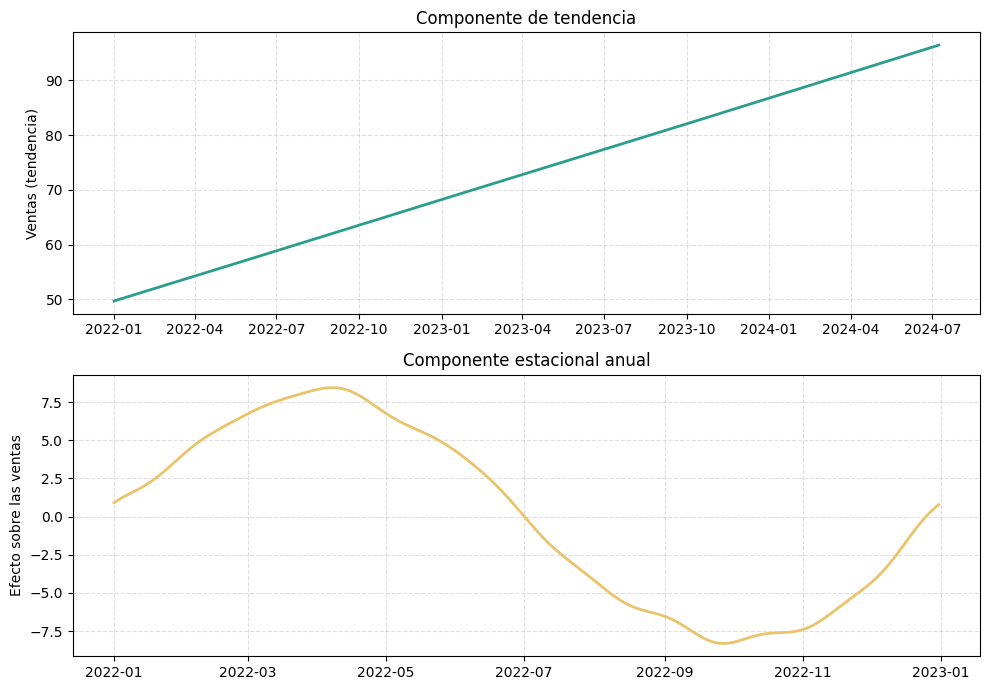

In [137]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
color_tendencia   = "#2a9d8f"
color_estacional  = "#e9c46a"
# ============================================

fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].plot(pronostico["ds"], pronostico["trend"], color=color_tendencia, linewidth=2)
axes[0].set_title("Componente de tendencia")
axes[0].set_ylabel("Ventas (tendencia)")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Mostramos un solo ciclo anual (365 días) para que se vea la forma de la curva
un_año = pronostico[pronostico["ds"] < pronostico["ds"].min() + pd.Timedelta(days=365)]
axes[1].plot(un_año["ds"], un_año["yearly"], color=color_estacional, linewidth=2)
axes[1].set_title("Componente estacional anual")
axes[1].set_ylabel("Efecto sobre las ventas")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 📦 Ejemplo real — Estacionalidad semanal (findes de semana más fuertes)

Simulamos un local donde los fines de semana se vende más, y le pedimos a Prophet que
detecte ese patrón semanal solo (sin pasarle explícitamente qué días son findes).

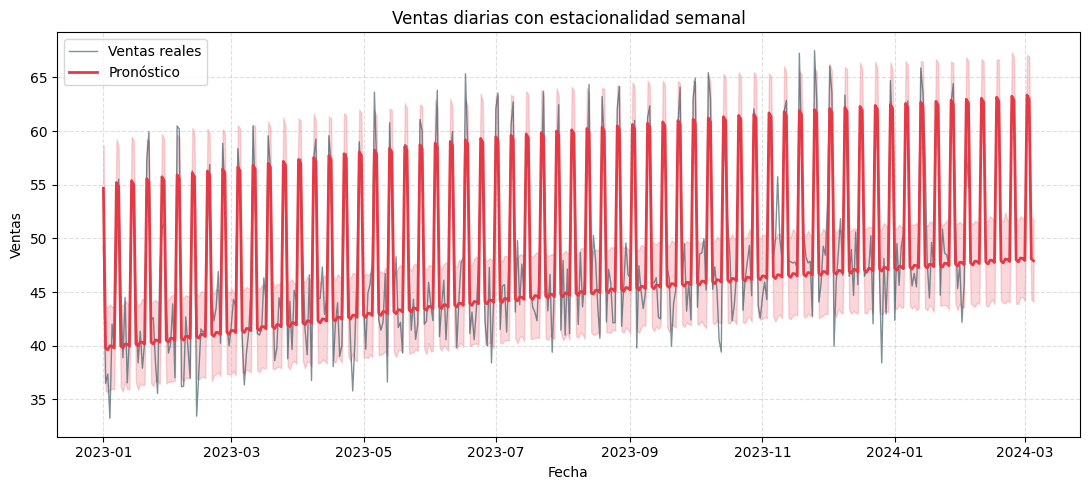

In [138]:
# ============================================
# 🎨 VARIABLES EDITABLES
# ============================================
cantidad_dias    = 400
efecto_finde     = 15      # ventas extra los sábados y domingos
dias_a_futuro    = 30

color_real       = "#264653"
color_pronostico = "#e63946"
# ============================================

fechas2 = pd.date_range("2023-01-01", periods=cantidad_dias, freq="D")
dia_semana = fechas2.dayofweek                      # 0=lunes ... 6=domingo
bono_finde = np.where(dia_semana >= 5, efecto_finde, 0)
ventas2 = 40 + 0.02 * np.arange(len(fechas2)) + bono_finde + rng.normal(0, 3, len(fechas2))

df_finde = pd.DataFrame({"ds": fechas2, "y": ventas2})

modelo_finde = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False)
modelo_finde.fit(df_finde)

futuro_finde = modelo_finde.make_future_dataframe(periods=dias_a_futuro)
pron_finde = modelo_finde.predict(futuro_finde)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df_finde["ds"], df_finde["y"], color=color_real, linewidth=1, alpha=0.6, label="Ventas reales")
ax.plot(pron_finde["ds"], pron_finde["yhat"], color=color_pronostico, linewidth=2, label="Pronóstico")
ax.fill_between(
    pron_finde["ds"], pron_finde["yhat_lower"], pron_finde["yhat_upper"],
    color=color_pronostico, alpha=0.2,
)
ax.set_title("Ventas diarias con estacionalidad semanal")
ax.set_xlabel("Fecha")
ax.set_ylabel("Ventas")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

✏️ **Ejercicio final de esta sección:**
1. Cambiá `efecto_finde` a `0` (sin diferencia entre findes y semana) y volvé a graficar.
   ¿El pronóstico se aplana?
2. Probá `Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
   changepoint_prior_scale=0.5)` (el valor por defecto es `0.05`) y compará qué tan "flexible"
   se vuelve la línea de tendencia ante los mismos datos.
3. **Desafío:** tomá el dataset de notas del Bloque 2 o el de MercadoLibre de tu proyecto y
   armá una serie de tiempo propia (por ejemplo, ventas por día) para pronosticar con este
   mismo patrón.